# LRLPR-26 · VÒNG 3 — mạng làm nét NHIỀU FRAME
**Ý tưởng:** ở vòng 1 và 2, mạng làm nét xử lý **từng frame riêng**, rồi mới gộp bằng cách bỏ phiếu ký tự. Mỗi frame của một track mang thêm chi tiết khác nhau
(chúng chỉ lệch nhau khoảng 0,6–1,1 pixel ở thang 16×48 — đã đo trên tập val), nên nếu đưa **cả 5 frame vào mạng cùng lúc** thì mạng có thể tự khôi phục chữ
mà một frame đơn lẻ không đủ thông tin. Đây là hướng duy nhất **thêm thông tin thật** thay vì chỉ đổi mục tiêu huấn luyện.

| Bước | Việc |
|---|---|
| W0 | Kiểm tra kết quả vòng 1 và 2 còn đủ trên Drive (không chạy lại) |
| W1 | Mở rộng lớp đầu của mạng 1 frame (M5c) lên 5 frame (15 kênh) và huấn luyện tiếp với L1 + VGG + **loss OCR** → nhánh **M6a** (và `M6a+` khi đọc bằng OCR vòng 2) |
| W2 | Chốt trên val trong tất cả các nhánh, chạy test **một lần** (khóa riêng) |
| W3 | Bảng so sánh, biểu đồ, ảnh các nhánh cạnh nhau, bằng chứng |

**Cần có trên Drive** (từ vòng 1 và 2): `splits/`, `ckpt/gplpr_ft.pth`, `ckpt/gplpr_sr.pth`, `ckpt/lpsrgan_M5c/best.pth`, `results/…`. Chạy **Run all** (GPU T4).
**Thời gian ước tính (chưa đo):** mỗi lần huấn luyện khoảng 20–25 phút (15 epoch, tốc độ tương tự vòng 2 vì nút thắt vẫn là CPU nạp ảnh); cộng đánh giá và tổng hợp khoảng 10 phút.
**Kỳ vọng thận trọng:** chưa biết gộp frame trong mạng có tốt hơn gộp bỏ phiếu hay không. Kết quả có thể tăng, giữ nguyên, hoặc giảm.

In [ ]:
# ===================== CẤU HÌNH (chỉ sửa khi thật sự cần) =====================
DRIVE_DIR = '/content/drive/MyDrive/MyCV'      # thư mục dự án trên "Drive của tôi" (My Drive)
ZIP_NAME  = 'LRLPR-26.zip'                     # tên file dataset nằm trong DRIVE_DIR
LOCAL     = '/content'                         # đĩa Colab (đọc/ghi nhanh) — GIỮ NGUYÊN, đừng đổi
SEED      = 42                                 # seed cố định để lặp lại được kết quả

TARGET_TOTAL_MIN = 60     # tổng thời gian mong muốn (phút) — dùng để TỰ chọn số epoch huấn luyện
OCR_EPOCHS = 8            # số epoch fine-tune OCR GP-LPR
SR_EPOCHS  = None         # số epoch fine-tune LPSRGAN; None = tự tính từ phép đo tốc độ
RUN_M4     = True         # có chạy nhánh tăng cường dữ liệu (M4) không? Đặt False nếu thiếu giờ
WORKERS    = 2            # số tiến trình nạp dữ liệu (Colab thường có 2 CPU)
VAL_TRACKS_FOR_TRAIN = 800  # số track val dùng để theo dõi trong lúc huấn luyện
START_FRESH = True        # True: bắt đầu bảng thời gian mới (nên bật khi chạy trọn quy trình)

# --- VÒNG 3: mạng làm nét NHIỀU FRAME (dùng lại kết quả vòng 1 và vòng 2 trên Drive) ---
MF_INIT = 'M5c'            # khởi tạo từ mạng 1 frame của vòng 2 (M5c = tốt nhất); 'M2' = trọng số công bố
MF_OCR_WEIGHTS = [3.0]     # mỗi giá trị = một lần huấn luyện (M6a, M6b, ...). Có thể thêm, ví dụ [1.0, 3.0]
MF_EPOCHS = 15             # số epoch mỗi lần huấn luyện
MF_LR = 1e-4               # learning rate
MF_CENTER_WEIGHT = 0.6     # trọng số khởi tạo của frame giữa khi mở rộng lớp đầu (các frame khác chia phần còn lại)

# --- Tham số ít khi cần đổi ---
RODOSOL_PATH    = f'{DRIVE_DIR}/models/Rodosol.pth'  # trọng số GP-LPR ban đầu
PRETRAINED_PATH = None    # None = tự tải trọng số LPSRGAN công bố; hoặc đường dẫn file có sẵn
VGG_PRETRAINED  = True    # dùng VGG19 đã học sẵn cho perceptual loss
MAX_TRAIN_TRACKS = 0      # 0 = dùng hết; chỉ đặt > 0 khi chạy thử nhanh
ALLOW_LOW_OCR   = False   # True = vẫn chạy tiếp dù OCR sau fine-tune < 70% (không khuyến nghị)
# ===============================================================================

import os, sys, json, time, subprocess, shutil
ZIP_PATH    = f'{DRIVE_DIR}/{ZIP_NAME}'
SPLIT_DIR   = f'{DRIVE_DIR}/splits'      # danh sách track train/val/test
RESULTS_DIR = f'{DRIVE_DIR}/results'     # kết quả các nhánh
EVID_DIR    = f'{DRIVE_DIR}/evidence'    # bằng chứng (thời gian, môi trường, mã băm...)
CKPT_DIR    = f'{DRIVE_DIR}/ckpt'        # checkpoint mô hình
CODE_DIR    = f'{LOCAL}/code'            # mã nguồn (ghi ở các ô bên dưới)
DATA_DIR    = f'{LOCAL}/data'            # dữ liệu giải nén
REPO_DIR    = f'{LOCAL}/lpsrgan'         # repo LPSRGAN

# Nối Google Drive (chỉ chạy được trên Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Không chạy trên Colab — bỏ qua bước nối Google Drive.')

for d in (SPLIT_DIR, RESULTS_DIR, EVID_DIR, CKPT_DIR, CODE_DIR):
    os.makedirs(d, exist_ok=True)
print('Đã sẵn sàng. Dự án trên Drive:', DRIVE_DIR)

Mounted at /content/drive
Đã sẵn sàng. Dự án trên Drive: /content/drive/MyDrive/MyCV


### Cài thư viện

In [ ]:
# Cài thư viện còn thiếu trên Colab (kornia dùng cho CLAHE; các thư viện khác Colab đã có sẵn)
%pip install -q kornia

### Mã nguồn dùng chung
Các ô dưới đây chỉ **ghi file mã nguồn** ra đĩa Colab (không chạy gì). Bản gốc nằm trong `02. Process/colab_src/`. Có thể bỏ qua, không cần đọc.

In [ ]:
%%writefile /content/code/lrlpr_common.py
# -*- coding: utf-8 -*-
"""
lrlpr_common.py — Thư viện DÙNG CHUNG cho các notebook của đồ án IT4343E
(Nhận diện biển số xe độ phân giải thấp, bộ dữ liệu LRLPR-26).

File này gom những việc mà nhiều notebook đều cần:
  1. Hằng số (kích thước ảnh, bảng chữ cái biển số...).
  2. Đọc danh sách track từ file split (train / val / test).
  3. Tiền xử lý ảnh (đệm cho đủ tỉ lệ 3:1, đổi kích thước, CLAHE) — GIỐNG HỆT repo LPSRGAN.
  4. Các lớp Dataset đọc ảnh theo track.
  5. Nạp / lưu mô hình OCR (GP-LPR) và mô hình làm nét (LPSRGAN).
  6. Gộp kết quả của 5 frame (bỏ phiếu) và các độ đo (Exact Match, độ đúng ký tự).
  7. Ghi bằng chứng: thời gian chạy từng bước, thông tin môi trường, mã băm file.

Quy ước: ảnh luôn là RGB, kiểu uint8, dạng (cao, rộng, 3), trừ khi ghi chú khác.
"""

import csv
import datetime
import hashlib
import json
import math
import os
import platform
import random
import subprocess
import sys
import time
from collections import Counter, defaultdict

import cv2
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset

# ----------------------------------------------------------------------------
# 1. HẰNG SỐ
# ----------------------------------------------------------------------------
ALPHABET = "0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ"  # 36 ký tự biển số (số + chữ hoa)
PLATE_LEN = 7                 # biển số Brazil/Mercosur đều có 7 ký tự
N_FRAMES = 5                  # mỗi track có 5 ảnh LR (và 5 ảnh HR ở tập train)
LR_H, LR_W = 16, 48           # kích thước ảnh LR đưa vào mạng làm nét (GAN)
SR_H, SR_W = 32, 96           # kích thước ảnh sau làm nét = kích thước đầu vào của OCR (gấp đôi LR)
ASPECT = 3.0                  # tỉ lệ rộng/cao chuẩn của biển số sau khi đệm
ASPECT_TOL = 0.15             # sai số cho phép quanh tỉ lệ chuẩn (giống repo)
PAD_COLOR = (127, 127, 127)   # màu xám dùng để đệm (giống repo)

# Tham số mặc định của mô hình OCR GP-LPR (lấy từ file cấu hình test của repo)
DEFAULT_GPLPR_ARGS = dict(alphabet=ALPHABET, nc=3, imgW=SR_W, imgH=SR_H, K=PLATE_LEN,
                          isSeqModel=True, head=2, inner=256, isl2Norm=True)

# Thứ tự 4 nhóm dữ liệu dùng khi báo cáo kết quả
GROUPS = ["Scenario-A/Brazilian", "Scenario-A/Mercosur",
          "Scenario-B/Brazilian", "Scenario-B/Mercosur"]


# ----------------------------------------------------------------------------
# 2. TIỆN ÍCH CHUNG: seed, thời gian, ghi file, mã băm
# ----------------------------------------------------------------------------
def set_seed(seed):
    """Đặt seed cho random / numpy / torch để kết quả lặp lại được."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def now_iso():
    """Giờ hiện tại dạng chuỗi, ví dụ '2026-11-13T09:30:15'."""
    return datetime.datetime.now().isoformat(timespec="seconds")


def fmt_seconds(s):
    """Đổi số giây thành dạng 'mm:ss' cho dễ đọc."""
    s = int(round(s))
    return f"{s // 60:02d}:{s % 60:02d}"


def write_json(path, obj):
    """Ghi dict ra file JSON (tự tạo thư mục nếu chưa có)."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)


def read_json(path):
    """Đọc file JSON thành dict."""
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def sha256_file(path):
    """Mã băm sha256 của một file — dùng làm bằng chứng file không bị sửa."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def run_script(cmd, env_extra=None):
    """
    Chạy một lệnh con (ví dụ: python train_ocr.py ...) và IN OUTPUT RA NGAY khi nó xuất hiện,
    để thấy tiến độ trong notebook. Nếu lệnh lỗi sẽ báo kèm 30 dòng cuối để dễ tìm nguyên nhân.
    """
    env = dict(os.environ, PYTHONUNBUFFERED="1", PYTHONIOENCODING="utf-8", NO_ALBUMENTATIONS_UPDATE="1")
    env.update(env_extra or {})
    p = subprocess.Popen([str(c) for c in cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
                         encoding="utf-8", errors="replace", env=env, bufsize=1)
    tail = []
    for line in p.stdout:
        print(line, end="")
        tail.append(line)
        tail = tail[-30:]
    rc = p.wait()
    if rc != 0:
        raise RuntimeError(f"Lệnh thất bại (mã thoát {rc}). 30 dòng cuối:\n" + "".join(tail))


def find_data_root(base):
    """Tìm thư mục chứa cả train/ và test/ (sau khi giải nén có thể nằm sâu thêm 1–2 cấp)."""
    base_depth = base.rstrip("/\\").count(os.sep)
    for r, dirs, _ in os.walk(base):
        if "train" in dirs and "test" in dirs:
            return r
        if r.rstrip("/\\").count(os.sep) - base_depth >= 3:
            dirs[:] = []  # không đi sâu quá
    return None


def ensure_dataset(zip_path, data_dir):
    """
    Bảo đảm dữ liệu đã được giải nén ở đĩa cục bộ (đọc nhanh hơn Drive rất nhiều). Trả về thư mục gốc dữ liệu.
    Có file đánh dấu '.extracted_ok' để biết lần giải nén trước đã hoàn tất (tránh dùng dữ liệu dở dang).
    """
    import shutil
    import zipfile
    marker = os.path.join(data_dir, ".extracted_ok")
    if os.path.exists(marker):
        root = find_data_root(data_dir)
        if root:
            print(f"Đã có dữ liệu giải nén sẵn: {root}")
            return root
    if not os.path.exists(zip_path):
        raise FileNotFoundError(
            f"Không thấy {zip_path}\n"
            'Lưu ý: nếu file nằm trong mục "Máy tính" (Computers) của Google Drive thì Colab KHÔNG đọc được. '
            'Hãy chép file zip vào "Drive của tôi" (My Drive) rồi sửa DRIVE_DIR / ZIP_NAME.')
    if os.path.isdir(data_dir):
        shutil.rmtree(data_dir)  # xóa bản giải nén dở dang
    os.makedirs(data_dir, exist_ok=True)
    local_zip = data_dir.rstrip("/\\") + "_tmp.zip"
    t0 = time.time()
    print(f"Chép {os.path.getsize(zip_path) / 1e6:.0f} MB từ Drive về đĩa cục bộ ...")
    shutil.copyfile(zip_path, local_zip)
    print(f"  chép xong ({time.time() - t0:.0f}s). Đang giải nén ...")
    if shutil.which("unzip"):
        subprocess.run(["unzip", "-q", "-o", local_zip, "-d", data_dir], check=True)
    else:
        with zipfile.ZipFile(local_zip) as z:
            z.extractall(data_dir)
    os.remove(local_zip)
    root = find_data_root(data_dir)
    if root is None:
        raise RuntimeError("Giải nén xong nhưng không thấy thư mục train/ và test/ — kiểm tra lại file zip.")
    open(marker, "w").close()
    print(f"Giải nén xong sau {time.time() - t0:.0f}s: {root}")
    return root


class StepTimer:
    """
    Đo thời gian một bước và ghi vào evidence/timing.csv (bằng chứng cho thầy).

    Cách dùng:
        with StepTimer("NB02 · Fine-tune OCR", evidence_dir):
            ...  # việc cần đo
    """

    def __init__(self, name, evidence_dir, filename="timing.csv"):
        self.name = name
        self.path = os.path.join(evidence_dir, filename)  # vòng 2 dùng file riêng: timing_v2.csv
        os.makedirs(evidence_dir, exist_ok=True)

    def __enter__(self):
        self.t0 = time.time()
        self.start = now_iso()
        print(f"▶ Bắt đầu: {self.name}  ({self.start})")
        return self

    def __exit__(self, exc_type, exc, tb):
        sec = time.time() - self.t0
        new_file = not os.path.exists(self.path)
        with open(self.path, "a", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if new_file:
                w.writerow(["step", "start", "end", "seconds", "status"])
            w.writerow([self.name, self.start, now_iso(), round(sec, 1),
                        "ok" if exc_type is None else f"loi:{exc_type.__name__}"])
        icon = "✔" if exc_type is None else "✘"
        print(f"{icon} Kết thúc: {self.name} — mất {fmt_seconds(sec)} ({sec:.0f} giây)")
        return False  # không nuốt lỗi


def save_environment(evidence_dir, tag):
    """
    Lưu thông tin môi trường chạy (GPU, phiên bản thư viện...) vào
    evidence/environment_<tag>.json — để chứng minh kết quả chạy trên máy nào.
    """
    from importlib import metadata
    libs = ["torch", "torchvision", "numpy", "opencv-python", "opencv-python-headless", "Pillow",
            "pandas", "kornia", "albumentations", "scikit-image", "matplotlib"]
    versions = {}
    for lib in libs:
        try:
            versions[lib] = metadata.version(lib)
        except Exception:  # noqa: BLE001 - thư viện không cài thì bỏ qua
            pass
    info = {
        "ghi_luc": now_iso(),
        "python": platform.python_version(),
        "he_dieu_hanh": platform.platform(),
        "torch_cuda_kha_dung": bool(torch.cuda.is_available()),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        "phien_ban_thu_vien": versions,
    }
    try:  # nvidia-smi chỉ có khi máy có GPU
        info["nvidia_smi"] = subprocess.run(["nvidia-smi"], capture_output=True, text=True,
                                            timeout=20).stdout
    except Exception:  # noqa: BLE001
        info["nvidia_smi"] = None
    write_json(os.path.join(evidence_dir, f"environment_{tag}.json"), info)
    return info


# ----------------------------------------------------------------------------
# 3. ĐỌC DANH SÁCH TRACK TỪ FILE SPLIT
# ----------------------------------------------------------------------------
def read_split_csv(path):
    """
    Đọc file split_*.csv (do notebook 00 tạo). Mỗi dòng là một track với các cột:
    split, scenario, layout, plate_text, track (đường dẫn tương đối trong thư mục dữ liệu).
    """
    with open(path, "r", encoding="utf-8") as f:
        return list(csv.DictReader(f))


def _detect_ext(track_dir, kind):
    """Tìm đuôi file (png/jpg) của ảnh '<kind>-001.*' trong một track. Trả về None nếu không có."""
    prefix = f"{kind}-001."
    for name in os.listdir(track_dir):
        if name.startswith(prefix):
            return name[len(prefix):]
    return None


def index_tracks(rows, data_root):
    """
    Bổ sung vào mỗi dòng: đường dẫn thư mục thật ('dir') và đuôi file ảnh LR/HR
    ('ext_lr', 'ext_hr'). Scenario-A dùng .png, Scenario-B dùng .jpg nên phải dò từng track.
    """
    out = []
    for r in rows:
        d = os.path.join(data_root, r["track"])
        r2 = dict(r)
        r2["dir"] = d
        r2["ext_lr"] = _detect_ext(d, "lr")
        r2["ext_hr"] = _detect_ext(d, "hr")
        out.append(r2)
    return out


def frame_path(row, kind, i):
    """Đường dẫn ảnh thứ i (1..5) của loại 'lr' hoặc 'hr' trong track."""
    ext = row["ext_lr"] if kind == "lr" else row["ext_hr"]
    return os.path.join(row["dir"], f"{kind}-{i:03d}.{ext}")


def group_of(row):
    """Tên nhóm của một track, ví dụ 'Scenario-B/Mercosur'."""
    return f'{row["scenario"]}/{row["layout"]}'


def stratified_subset(rows, n, seed=0):
    """
    Lấy ngẫu nhiên (cố định theo seed) n track nhưng GIỮ ĐÚNG TỈ LỆ các nhóm Scenario × layout.
    Dùng để theo dõi val trong lúc huấn luyện. (Lần chạy đầu từng lấy "n track đầu tiên", mà file được
    sắp theo đường dẫn nên toàn bộ là Scenario-A/Brazilian — tức không có ảnh ban đêm nào.)
    """
    if n <= 0 or n >= len(rows):
        return rows
    rng = random.Random(seed)
    by_group = defaultdict(list)
    for i, r in enumerate(rows):
        by_group[group_of(r)].append(i)
    picked = []
    for _g, idx in sorted(by_group.items()):
        k = max(1, round(n * len(idx) / len(rows)))
        picked += rng.sample(idx, min(k, len(idx)))
    return [rows[i] for i in sorted(picked)]


# ----------------------------------------------------------------------------
# 4. TIỀN XỬ LÝ ẢNH (giống hệt repo LPSRGAN)
# ----------------------------------------------------------------------------
def read_rgb(path):
    """Đọc ảnh và đổi sang RGB (OpenCV mặc định đọc BGR)."""
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def pad_to_ratio(img, ratio=ASPECT, tol=ASPECT_TOL, color=PAD_COLOR):
    """
    Đệm viền xám để tỉ lệ rộng/cao nằm trong [ratio - tol, ratio + tol], KHÔNG làm méo ký tự.
    Kết quả giống hàm pad_with_mask của repo (nhưng tính trực tiếp, không dùng vòng lặp từng pixel).
    """
    h, w = img.shape[:2]
    lo, hi = ratio - tol, ratio + tol
    if lo <= w / h <= hi:
        return img
    bw = bh = 0
    if w / h < lo:  # ảnh quá "vuông": đệm thêm hai bên trái/phải
        bw = max(0, int(math.ceil(lo * h - w)))
        while (w + bw) / h < lo:
            bw += 1
        while bw > 0 and (w + bw - 1) / h >= lo:
            bw -= 1
    else:           # ảnh quá "dài": đệm thêm hai bên trên/dưới
        bh = max(0, int(math.ceil(w / hi - h)))
        while w / (h + bh) > hi:
            bh += 1
        while bh > 0 and w / (h + bh - 1) <= hi:
            bh -= 1
    bw //= 2   # chia đều hai phía (đúng như repo)
    bh //= 2
    return cv2.copyMakeBorder(img, bh, bh, bw, bw, cv2.BORDER_CONSTANT, value=color)


def _bicubic():
    """Hằng số nội suy bicubic của Pillow (tương thích nhiều phiên bản)."""
    return getattr(getattr(Image, "Resampling", Image), "BICUBIC")


def resize_u8(img, out_h, out_w):
    """Đổi kích thước bằng nội suy bicubic (Pillow), giữ kiểu uint8 — giống torchvision.Resize của repo."""
    return np.array(Image.fromarray(img).resize((out_w, out_h), _bicubic()))  # np.array = bản sao ghi được


def to_chw_float(img_u8):
    """Ảnh uint8 (cao, rộng, 3) -> mảng float32 (3, cao, rộng) trong khoảng [0, 1]."""
    return (img_u8.astype(np.float32) / 255.0).transpose(2, 0, 1).copy()


def clahe_hr(img_u8, clip=4.0, grid=(2, 2)):
    """
    Cân bằng histogram thích ứng (CLAHE) bằng kornia — đúng như repo áp lên ảnh HR mục tiêu.
    Mục đích: ảnh HR có độ tương phản đồng đều hơn để mạng làm nét học theo.
    """
    import kornia
    t = torch.from_numpy(np.ascontiguousarray(img_u8)).permute(2, 0, 1).float().div(255.0).unsqueeze(0)
    out = kornia.enhance.equalize_clahe(t, clip_limit=clip, grid_size=grid)
    return out.mul(255.0).byte()[0].permute(1, 2, 0).contiguous().numpy()


def prep_lr_u8(img):
    """Ảnh LR gốc -> đệm tỉ lệ -> thu về 16x48 (đầu vào của mạng làm nét). Trả về uint8."""
    return resize_u8(pad_to_ratio(img), LR_H, LR_W)


def prep_hr_u8(img):
    """Ảnh HR gốc -> CLAHE -> đệm tỉ lệ -> 32x96 (ảnh đích của mạng làm nét). Trả về uint8."""
    return resize_u8(pad_to_ratio(clahe_hr(img)), SR_H, SR_W)


def prep_plain_u8(img):
    """Ảnh gốc -> đệm tỉ lệ -> 32x96 (KHÔNG làm nét). Dùng cho mốc M0."""
    return resize_u8(pad_to_ratio(img), SR_H, SR_W)


def _rotate(img, angle):
    """Xoay ảnh quanh tâm một góc nhỏ (độ), phần viền thiếu được lấp bằng pixel biên."""
    h, w = img.shape[:2]
    m = cv2.getRotationMatrix2D((w / 2.0, h / 2.0), angle, 1.0)
    return cv2.warpAffine(img, m, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)


def augment_pair(lr, hr, rng, fog_p=0.3):
    """
    TĂNG CƯỜNG DỮ LIỆU cho một cặp (LR, HR). Mỗi lần chọn NGẪU NHIÊN một phép (giống tinh thần augment của repo):
      0  xoay nhẹ ±2°  — áp cho CẢ LR và HR với CÙNG một góc (để hai ảnh vẫn khớp nhau)
      1  đổi độ sáng / tương phản   — chỉ áp lên LR
      2  đổi gamma (0.8 – 1.2)       — chỉ áp lên LR
      3  làm nét nhẹ (unsharp mask)  — chỉ áp lên LR
      4  giữ nguyên (xác suất nhỏ)
    Sau đó, với xác suất fog_p, thêm sương mù lên LR (theo gợi ý của thầy).
    Chỉ biến đổi LR vì ảnh HR là đáp án thật: nó không nên bị làm xấu hay đổi màu.

    GHI CHÚ: không dùng hàm augment của repo vì nó có lỗi — khi chọn phép xoay (SafeRotate) ảnh HR bị
    co về kích thước ảnh LR (ví dụ 45x130 thành 20x57), làm cặp huấn luyện bị hỏng và HR bị mờ.
    rng: module random hoặc random.Random.
    """
    choice = rng.choices(range(5), weights=[1, 1, 1, 1, 0.1])[0]
    if choice == 0:
        ang = rng.uniform(-2.0, 2.0)
        lr, hr = _rotate(lr, ang), _rotate(hr, ang)
    elif choice == 1:
        alpha = 1.0 + rng.uniform(-0.2, 0.2)     # tương phản
        beta = 1.0 + rng.uniform(-0.1, 0.1)      # độ sáng
        lr = np.clip(lr.astype(np.float32) * alpha * beta, 0, 255).astype(np.uint8)
    elif choice == 2:
        gamma = rng.uniform(0.8, 1.2)
        lut = (np.linspace(0, 1, 256) ** (1.0 / gamma) * 255).astype(np.uint8)
        lr = cv2.LUT(lr, lut)
    elif choice == 3:
        a = rng.uniform(0.2, 0.5)
        blur = cv2.GaussianBlur(lr, (3, 3), 0)
        lr = np.clip(lr.astype(np.float32) + a * (lr.astype(np.float32) - blur), 0, 255).astype(np.uint8)
    if rng.random() < fog_p:
        lr = add_fog(lr, rng)
    return lr, hr


def add_fog(img, rng):
    """
    Thêm 'sương mù' nhẹ vào ảnh LR (tăng cường dữ liệu theo gợi ý của thầy):
    pha ảnh với một lớp sáng đều rồi làm mờ rất nhẹ -> giảm tương phản như khi trời sương.
    rng là đối tượng random.Random để kết quả lặp lại được.
    """
    alpha = rng.uniform(0.10, 0.35)        # độ dày sương
    airlight = rng.uniform(200, 255)       # độ sáng của lớp sương
    fogged = img.astype(np.float32) * (1 - alpha) + airlight * alpha
    fogged = cv2.GaussianBlur(fogged, (3, 3), 0.5)
    return np.clip(fogged, 0, 255).astype(np.uint8)


# ----------------------------------------------------------------------------
# 5. BỘ LÀM NÉT CỔ ĐIỂN (CV) — mốc M1, tham số lấy từ run_cv_baseline_experiment.py
# ----------------------------------------------------------------------------
def cv_pipeline_rgb(img_rgb):
    """
    Pipeline thị giác máy tính cổ điển: CLAHE -> lọc Bilateral -> Unsharp Mask.
    Đầu vào / đầu ra: ảnh RGB uint8 (bên trong đổi sang BGR cho giống code thực nghiệm cũ).
    """
    bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    # Bước 1: CLAHE trên kênh sáng (L) để kéo sáng vùng tối
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(4, 4)).apply(l)
    bgr = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)
    # Bước 2: khử nhiễu hạt nhưng giữ viền chữ
    bgr = cv2.bilateralFilter(bgr, d=5, sigmaColor=30, sigmaSpace=30)
    # Bước 3: làm nổi viền chữ bằng Unsharp Mask
    blurred = cv2.GaussianBlur(bgr, (5, 5), 0.8)
    sharp = 2.8 * bgr.astype(np.float32) - 1.8 * blurred.astype(np.float32)
    bgr = np.clip(sharp, 0, 255).astype(np.uint8)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


# ----------------------------------------------------------------------------
# 6. CÁC LỚP DATASET
# ----------------------------------------------------------------------------
def worker_init_fn(worker_id):
    """Chạy khi khởi tạo mỗi tiến trình nạp dữ liệu: đặt seed riêng và giới hạn luồng tính toán."""
    torch.set_num_threads(1)
    base = torch.initial_seed() % (2 ** 31)
    random.seed(base)
    np.random.seed(base)


class SRPairDataset(Dataset):
    """
    Dataset cặp (LR, HR) để huấn luyện / kiểm tra mạng làm nét.
    Mỗi mẫu = một track; chọn một frame (ngẫu nhiên hoặc cố định) rồi tiền xử lý.
    Trả về: (ảnh LR 3x16x48, ảnh HR 3x32x96, chuỗi biển số).

    aug=True  -> tăng cường dữ liệu bằng augment_pair(): xoay nhẹ (cả LR+HR), đổi sáng/tương phản,
                 gamma, làm nét nhẹ và sương mù (xác suất fog_p) — các phép đổi ảnh chỉ áp lên LR.
    """

    def __init__(self, rows, frame="random", aug=False, fog_p=0.3):
        self.rows = rows
        self.frame = frame
        self.aug = aug
        self.fog_p = fog_p

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        i = random.randint(1, N_FRAMES) if self.frame == "random" else int(self.frame)
        lr = read_rgb(frame_path(r, "lr", i))
        hr = read_rgb(frame_path(r, "hr", i))
        if self.aug:
            lr, hr = augment_pair(lr, hr, random, self.fog_p)
        lr_t = torch.from_numpy(to_chw_float(prep_lr_u8(lr)))
        hr_t = torch.from_numpy(to_chw_float(prep_hr_u8(hr)))
        return lr_t, hr_t, r["plate_text"]


class HRPlateDataset(Dataset):
    """Dataset ảnh HR (đã CLAHE + đệm + 32x96) và biển số — để huấn luyện / kiểm tra OCR."""

    def __init__(self, rows, frame="random"):
        self.rows = rows
        self.frame = frame

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        i = random.randint(1, N_FRAMES) if self.frame == "random" else int(self.frame)
        hr_u8 = prep_hr_u8(read_rgb(frame_path(r, "hr", i)))
        return torch.from_numpy(hr_u8), r["plate_text"]  # uint8 (32, 96, 3)


class LRFramesDataset(Dataset):
    """Dataset trả về cả 5 frame LR đã tiền xử lý (5x3x16x48) của một track — để chạy mạng làm nét."""

    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        frames = [to_chw_float(prep_lr_u8(read_rgb(frame_path(r, "lr", i))))
                  for i in range(1, N_FRAMES + 1)]
        return torch.from_numpy(np.stack(frames)), idx


class MFPairDataset(Dataset):
    """
    Dataset cho mạng làm nét NHIỀU FRAME: mỗi mẫu = một track.
    Đầu vào: chồng 5 frame LR đã tiền xử lý, ghép theo kênh -> tensor (15, 16, 48).
    Đích   : ảnh HR (CLAHE, 32x96) của frame đứng GIỮA trong thứ tự đưa vào.
    order='random': mỗi lần xoay vòng thứ tự frame ngẫu nhiên (frame nào làm 'tâm' cũng được) để mạng
                    không phụ thuộc vào vị trí cố định; order='fixed': luôn thứ tự 1..5 (dùng cho val).
    Trả về: (chồng LR 15x16x48, ảnh HR 3x32x96, chuỗi biển số).
    """

    def __init__(self, rows, order="random"):
        self.rows = rows
        self.order = order

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        r = self.rows[idx]
        shift = random.randrange(N_FRAMES) if self.order == "random" else 0
        frames = [(shift + k) % N_FRAMES + 1 for k in range(N_FRAMES)]  # số frame (1..5) theo thứ tự đưa vào
        center = frames[N_FRAMES // 2]
        lr = np.concatenate([to_chw_float(prep_lr_u8(read_rgb(frame_path(r, "lr", f)))) for f in frames], axis=0)
        hr = to_chw_float(prep_hr_u8(read_rgb(frame_path(r, "hr", center))))
        return torch.from_numpy(lr), torch.from_numpy(hr), r["plate_text"]


# ----------------------------------------------------------------------------
# 7. NẠP / LƯU MÔ HÌNH (cần repo LPSRGAN đã nằm trong sys.path)
# ----------------------------------------------------------------------------
def add_repo_to_path(repo_dir):
    """Cho Python thấy các package của repo LPSRGAN (models, datasets, ...)."""
    if repo_dir not in sys.path:
        sys.path.insert(0, repo_dir)


def atomic_torch_save(obj, path):
    """Lưu checkpoint an toàn: ghi ra file tạm rồi đổi tên, tránh file hỏng nếu bị ngắt giữa chừng."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def _strip_module_prefix(sd):
    """Bỏ tiền tố 'module.' (do DataParallel thêm vào) nếu có."""
    return {(k[7:] if k.startswith("module.") else k): v for k, v in sd.items()}


def load_gplpr(repo_dir, ckpt_path, device, verbose=True):
    """
    Nạp mô hình OCR GP-LPR từ checkpoint. Hỗ trợ 3 dạng file:
      (a) dạng của repo:  {'model': {'name', 'args', 'sd'}, ...}
      (b) dạng {'state_dict': ...}
      (c) state_dict thuần (chỉ gồm tensor)
    Trả về (model, thông_tin). Báo LỖI nếu thiếu / thừa tham số (tránh nạp sai âm thầm).
    """
    add_repo_to_path(repo_dir)
    import models  # package của repo
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    args = dict(DEFAULT_GPLPR_ARGS)
    if isinstance(ck, dict) and isinstance(ck.get("model"), dict) and "sd" in ck["model"]:
        sd = ck["model"]["sd"]
        args.update(ck["model"].get("args", {}) or {})
        kind = "repo"
    elif isinstance(ck, dict) and "state_dict" in ck:
        sd, kind = ck["state_dict"], "state_dict"
    elif isinstance(ck, dict) and ck and all(torch.is_tensor(v) for v in ck.values()):
        sd, kind = ck, "thuan"
    else:
        keys = list(ck.keys())[:10] if isinstance(ck, dict) else type(ck)
        raise ValueError(f"Không nhận ra định dạng checkpoint {ckpt_path}. Các khóa: {keys}")
    model = models.make({"name": "GPLPR", "args": args})
    res = model.load_state_dict(_strip_module_prefix(sd), strict=False)
    info = {"file": ckpt_path, "dinh_dang": kind, "thieu": len(res.missing_keys),
            "thua": len(res.unexpected_keys), "so_tham_so": sum(p.numel() for p in model.parameters())}
    if verbose:
        print(f"[GP-LPR] nạp {os.path.basename(ckpt_path)} (dạng: {kind}) — thiếu {info['thieu']}, "
              f"thừa {info['thua']} khóa, {info['so_tham_so']:,} tham số")
    if info["thieu"] > 0:
        raise ValueError(f"Checkpoint thiếu {info['thieu']} khóa, ví dụ: {res.missing_keys[:5]}")
    return model.to(device).eval(), info


def save_gplpr(model, path, extra=None):
    """Lưu GP-LPR theo định dạng của repo ({'model': {'name','args','sd'}, ...})."""
    sd = {k: v.detach().cpu() for k, v in model.state_dict().items()}
    obj = {"model": {"name": "GPLPR", "args": dict(DEFAULT_GPLPR_ARGS), "sd": sd}}
    if extra:
        obj.update(extra)
    atomic_torch_save(obj, path)


def inflate_first_conv(g, n_frames, center_weight=0.6):
    """
    Biến mạng làm nét 1 frame thành mạng NHIỀU FRAME bằng cách mở rộng lớp tích chập đầu tiên
    từ 3 kênh (1 ảnh RGB) lên 3*n_frames kênh (n ảnh chồng theo kênh).
    Trọng số khởi tạo: frame GIỮA nhận center_weight * W, mỗi frame còn lại nhận
    (1 - center_weight)/(n-1) * W (W = trọng số đã học của mạng 1 frame, tổng các phần = W).
    Nhờ vậy lúc bắt đầu mạng mới hành xử gần giống mạng 1 frame đã tốt rồi mới học tận dụng các frame còn lại.
    """
    old = g.conv_first
    assert old.in_channels == 3, "Mạng đã là nhiều frame"
    new = torch.nn.Conv2d(3 * n_frames, old.out_channels, old.kernel_size, padding=old.padding)
    with torch.no_grad():
        w = old.weight.detach()
        other = (1.0 - center_weight) / (n_frames - 1)
        for k in range(n_frames):
            new.weight[:, 3 * k:3 * k + 3] = w * (center_weight if k == n_frames // 2 else other)
        new.bias.copy_(old.bias.detach())
    g.conv_first = new.to(old.weight.device)
    return g


def load_generator(repo_dir, ckpt_path, device):
    """
    Nạp mạng làm nét LPSRGAN (generator) từ checkpoint theo định dạng repo.
    Dùng load_state_dict(strict=True) để CHẮC CHẮN trọng số đã được nạp đúng
    (hàm models.make của repo nuốt lỗi âm thầm nên không dùng đường đó).
    Nếu checkpoint là mạng NHIỀU FRAME (có khóa 'n_frames' > 1) thì dựng lớp đầu nhiều kênh trước khi nạp.
    """
    add_repo_to_path(repo_dir)
    import models
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    spec = ck["model"]
    args = spec.get("args") or {"num_blocks": 3, "dropout_prob": 0.5}
    g, _d = models.make({"name": "lpsrgan", "args": args})
    n = int(spec.get("n_frames", 1))
    if n > 1:
        g.conv_first = torch.nn.Conv2d(3 * n, g.conv_first.out_channels, g.conv_first.kernel_size,
                                       padding=g.conv_first.padding)
    g.load_state_dict(_strip_module_prefix(spec["sd"]), strict=True)
    return g.to(device).eval(), ck


@torch.no_grad()
def ocr_read(ocr, frames_u8, device, bs=600):
    """
    Cho OCR đọc một loạt ảnh.
    frames_u8: mảng uint8 (N, 32, 96, 3). Trả về (danh sách N chuỗi, mảng N độ tin cậy).
    """
    preds, confs = [], []
    ocr.eval()
    for s in range(0, len(frames_u8), bs):
        x = torch.from_numpy(frames_u8[s:s + bs]).to(device).permute(0, 3, 1, 2).float().div(255.0)
        p, c = ocr.OCR_pred(x)
        preds.extend(p)
        confs.extend(c.tolist())
    return preds, np.array(confs, dtype=np.float32)


# ----------------------------------------------------------------------------
# 8. GỘP 5 FRAME (bỏ phiếu) — giống hệt utils_test của repo
# ----------------------------------------------------------------------------
def fuse_mvcp(preds, k):
    """Bỏ phiếu từng ký tự: ở mỗi vị trí chọn ký tự xuất hiện nhiều nhất trong k frame đầu."""
    if k == 1:
        return preds[0]
    return "".join(Counter(chars).most_common(1)[0][0] for chars in zip(*preds[:k]))


def fuse_hc(confs, preds, k):
    """Chọn chuỗi của frame có độ tin cậy cao nhất trong k frame đầu."""
    if k == 1:
        return preds[0]
    c = list(confs[:k])
    return preds[:k][int(np.argmax(c))]


def fuse_mv(confs, preds, k):
    """Chọn chuỗi xuất hiện nhiều lần nhất trong k frame đầu; nếu hòa thì lấy chuỗi tin cậy cao hơn."""
    if k == 1:
        return preds[0]
    s, c = list(preds[:k]), list(confs[:k])
    counts = Counter(s)
    top = max(counts.values())
    best = [x for x, n in counts.items() if n == top]
    if len(best) == 1:
        return best[0]
    idx = max((i for i, x in enumerate(s) if x in best), key=lambda i: c[i])
    return s[idx]


FUSIONS = {"mvcp": lambda p, c, k: fuse_mvcp(p, k),
           "hc": lambda p, c, k: fuse_hc(c, p, k),
           "mv": lambda p, c, k: fuse_mv(c, p, k)}
FUSION_KS = (3, 5)  # gộp 3 frame đầu hoặc cả 5 frame


# ----------------------------------------------------------------------------
# 9. ĐỘ ĐO
# ----------------------------------------------------------------------------
def exact_match(pred, gt):
    """1 nếu đọc đúng TOÀN BỘ biển số, ngược lại 0."""
    return int(pred == gt)


def char_correct(pred, gt):
    """Số ký tự đúng đúng vị trí (so từng vị trí với nhãn thật)."""
    return sum(1 for a, b in zip(pred, gt) if a == b)


def char_accuracy(pred, gt):
    """Tỉ lệ ký tự đúng trên độ dài nhãn thật (0..1)."""
    return char_correct(pred, gt) / max(1, len(gt))


Writing /content/code/lrlpr_common.py


In [ ]:
%%writefile /content/code/setup_repo.py
# -*- coding: utf-8 -*-
"""
setup_repo.py — Chuẩn bị repo LPSRGAN trên Colab.

Việc làm:
  1. Tải repo https://github.com/valfride/lpsrgan về đúng commit đã dùng khi lập kế hoạch
     (để kết quả không đổi nếu tác giả cập nhật code sau này).
  2. Áp MỘT bản vá nhỏ lên repo (xem apply_patches) rồi ghi lại vào evidence/patches.log.
  3. Tải trọng số LPSRGAN đã công bố (nếu chưa có).

Tất cả các hàm đều "idempotent": chạy lại nhiều lần không gây hại.
"""

import os
import subprocess
import urllib.request

REPO_URL = "https://github.com/valfride/lpsrgan.git"
REPO_COMMIT = "68fc78aa12bd9becf6ab322b3dacd890fab928a1"
PRETRAINED_URL = ("https://github.com/valfride/lpsrgan/releases/download/"
                  "LPSRGAN_pre_trained_model/best_model_Epoch_116.pth")


def _log(msg, log_path):
    """In ra màn hình và ghi thêm vào file nhật ký vá lỗi."""
    print(msg)
    if log_path:
        os.makedirs(os.path.dirname(os.path.abspath(log_path)), exist_ok=True)
        with open(log_path, "a", encoding="utf-8") as f:
            f.write(msg + "\n")


def clone_repo(repo_dir, log_path=None):
    """Tải repo về thư mục repo_dir và chuyển sang đúng commit. Bỏ qua nếu đã có."""
    if os.path.isdir(os.path.join(repo_dir, ".git")):
        _log(f"[repo] đã có sẵn {repo_dir}, bỏ qua bước tải", log_path)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, repo_dir], check=True)
        _log(f"[repo] đã tải {REPO_URL} -> {repo_dir}", log_path)
    subprocess.run(["git", "-C", repo_dir, "checkout", "-q", REPO_COMMIT], check=True)
    head = subprocess.run(["git", "-C", repo_dir, "rev-parse", "HEAD"], capture_output=True,
                          text=True, check=True).stdout.strip()
    assert head == REPO_COMMIT, f"Sai commit: {head}"
    _log(f"[repo] đang ở commit {head}", log_path)


def _comment_out_line(repo_dir, rel_path, target, tag, why, log_path):
    """
    Vô hiệu hóa (đưa thành chú thích) dòng 'target' trong file rel_path của repo.
    Có kiểm tra (assert) để biết ngay nếu repo đã khác so với dự kiến.
    """
    path = os.path.join(repo_dir, rel_path)
    with open(path, "r", encoding="utf-8", newline="") as f:
        text = f.read()
    marker = "# (da bo) " + target
    if marker in text:
        _log(f"[vá {tag}] {rel_path}: đã vá từ trước, bỏ qua", log_path)
        return
    assert target in text, f"Không thấy dòng cần vá trong {rel_path} (repo đã đổi?)"
    new_text = text.replace(target, marker + "  # " + why, 1)
    assert marker in new_text
    with open(path, "w", encoding="utf-8", newline="") as f:
        f.write(new_text)
    _log(f"[vá {tag}] {rel_path}: đã bỏ '{target}' ({why})", log_path)


def apply_patches(repo_dir, log_path=None):
    """
    Hai bản vá nhỏ, chỉ để repo import được trên Colab mà không cần thư viện thừa:

      P1  models/__init__.py : bỏ 'from . import ocr_rodosol'
          Lý do: file đó import keras/tensorflow (OCR Keras của tác giả) mà ta không dùng;
          giữ lại sẽ kéo theo TensorFlow và dễ xung đột phiên bản.
      P2  models/lpsrgan_arch.py : bỏ 'from basicsr.archs.rrdbnet_arch import RRDBNet'
          Lý do: thư viện basicsr rất nặng, hay lỗi khi cài, và RRDBNet KHÔNG được dùng
          ở bất kỳ đâu trong file (chỉ import cho có).
    """
    _comment_out_line(repo_dir, os.path.join("models", "__init__.py"),
                      "from . import ocr_rodosol", "P1", "tránh kéo theo TensorFlow", log_path)
    _comment_out_line(repo_dir, os.path.join("models", "lpsrgan_arch.py"),
                      "from basicsr.archs.rrdbnet_arch import RRDBNet", "P2",
                      "basicsr nặng và không được dùng", log_path)


def download(url, dest, log_path=None):
    """Tải một file về dest (bỏ qua nếu đã có)."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        _log(f"[tải] đã có {dest}", log_path)
        return dest
    os.makedirs(os.path.dirname(os.path.abspath(dest)), exist_ok=True)
    tmp = dest + ".tmp"
    urllib.request.urlretrieve(url, tmp)
    os.replace(tmp, dest)
    _log(f"[tải] {url} -> {dest} ({os.path.getsize(dest) / 1e6:.1f} MB)", log_path)
    return dest


def setup(repo_dir, evidence_dir=None):
    """Tải repo đúng commit + áp bản vá. Trả về repo_dir."""
    log_path = os.path.join(evidence_dir, "patches.log") if evidence_dir else None
    clone_repo(repo_dir, log_path)
    apply_patches(repo_dir, log_path)
    return repo_dir


Writing /content/code/setup_repo.py


In [ ]:
%%writefile /content/code/train_ft.py
# -*- coding: utf-8 -*-
"""
train_ft.py — Fine-tune mạng làm nét LPSRGAN (Notebook 03). Thay cho train.py của repo.

VÌ SAO KHÔNG DÙNG train.py CỦA REPO?
  train.py gốc có nhiều chỗ làm hỏng / làm chậm trên Colab: ép CUDA_VISIBLE_DEVICES="1",
  bật set_detect_anomaly(True) (rất chậm), num_workers=0, chạy vòng pre-train 1000 lượt ở epoch 1,
  vẽ ảnh mỗi 3 bước, gửi email cuối cùng, và cần OCR Keras không có sẵn.

LOSS (giống hành vi THỰC của repo, cộng thêm phần tuỳ chọn):
  Loss của generator = L1 + VGG19 perceptual.
  (Trong code gốc, phần adversarial và OCR loss không tạo ra gradient nên không ảnh hưởng generator.)
  --ocr_weight > 0 : thêm LOSS OCR CÓ GRADIENT THẬT (cross-entropy của OCR đóng băng) như bài báo
                     LPSRGAN / LCOFL — ép mạng làm nét vẽ ra chữ mà OCR đọc được. Mặc định 0 (tắt).
  --adv_weight > 0 : thêm thành phần adversarial (LSGAN) như bài báo — mặc định 0 (tắt).

NHIỀU FRAME (--mf 1):
  Thay vì làm nét từng frame riêng, đưa chồng 5 frame LR của một track vào mạng cùng lúc (15 kênh).
  Mỗi frame mang thêm chi tiết khác nhau nên mạng có thể khôi phục chữ mà một frame đơn lẻ không đủ thông tin.
  Lớp đầu của mạng 1 frame đã học được "mở rộng" (inflate_first_conv) để khởi đầu từ mạng tốt sẵn có.

TĂNG CƯỜNG DỮ LIỆU (--aug 1):
  xoay nhẹ ±2° (cả LR+HR, cùng góc), đổi sáng/tương phản, gamma, làm nét nhẹ và sương mù — các phép
  đổi ảnh chỉ áp lên LR (xem lrlpr_common.augment_pair; không dùng augment của repo vì repo làm hỏng ảnh HR).

Đầu ra trong thư mục --out:
  best.pth, last.pth        : checkpoint (định dạng repo, nạp được bằng lrlpr_common.load_generator)
  train_log.csv             : log từng epoch (loss, PSNR, Exact Match 1 frame, thời gian)
  run_config.json           : toàn bộ tham số + mã băm (bằng chứng)
  calibration.json          : (chỉ khi dùng --calibrate) tốc độ đo được
"""

import argparse
import csv
import math
import os
import sys
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402


# ----------------------------------------------------------------------------
# Perceptual loss VGG19 (sao chép từ losses/lossPack.py của repo, bỏ phần TensorFlow và .cuda() cứng)
# ----------------------------------------------------------------------------
class VGG19Perceptual(nn.Module):
    """
    So sánh ảnh SR và ảnh HR ở nhiều tầng đặc trưng của VGG19 (đã học sẵn trên ImageNet).
    Giúp ảnh sinh ra giống ảnh thật về hình dạng nét chữ, không chỉ giống từng điểm ảnh.
    """

    def __init__(self, pretrained=True, weights=(0.1, 0.1, 1.0, 1.0, 1.0)):
        super().__init__()
        from torchvision.models import vgg19
        try:
            from torchvision.models import VGG19_Weights
            vgg = vgg19(weights=VGG19_Weights.IMAGENET1K_V1 if pretrained else None)
        except ImportError:  # torchvision cũ
            vgg = vgg19(pretrained=pretrained)
        feats = vgg.features.eval()
        cuts = [3, 8, 17, 26, 35]  # conv1_2, conv2_2, conv3_4, conv4_4, conv5_4 (như repo)
        blocks, last = [], 0
        for c in cuts:
            blocks.append(feats[last:c + 1])
            last = c + 1
        self.blocks = nn.ModuleList(blocks)
        for p in self.parameters():
            p.requires_grad = False
        self.weights = weights
        self.l1 = nn.L1Loss()

    def _features(self, x):
        x = (x - 0.45) / 0.225  # chuẩn hóa đơn giản giống repo
        outs = []
        for b in self.blocks:
            x = b(x)
            outs.append(x)
        return outs

    def forward(self, sr, hr):
        loss = 0.0
        for w, a, b in zip(self.weights, self._features(sr), self._features(hr)):
            loss = loss + w * self.l1(a, b)
        return loss


# ----------------------------------------------------------------------------
# Kiểm tra trên val
# ----------------------------------------------------------------------------
@torch.no_grad()
def validate(G, loader, ocr, device):
    """Tính L1, PSNR và (nếu có OCR) Exact Match 1 frame của ảnh SR trên tập val."""
    G.eval()
    l1s, psnrs, ok, n = [], [], 0, 0
    for lr, hr, gt in loader:
        lr, hr = lr.to(device), hr.to(device)
        sr = G(lr)
        l1s.append(torch.mean(torch.abs(sr - hr)).item())
        srq = sr.clamp(0, 1)
        mse = torch.mean((srq - hr) ** 2, dim=(1, 2, 3)).clamp_min(1e-10)
        psnrs.extend((10 * torch.log10(1.0 / mse)).tolist())
        if ocr is not None:
            u8 = (srq * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()
            preds, _ = C.ocr_read(ocr, u8, device)
            ok += sum(int(p == g) for p, g in zip(preds, gt))
        n += len(gt)
    return {"val_l1": float(np.mean(l1s)), "val_psnr": float(np.mean(psnrs)),
            "val_em": (ok / n) if ocr is not None else float("nan")}


def make_scaler(enabled):
    """GradScaler tương thích nhiều phiên bản PyTorch."""
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def cosine_lr(step, total, lr0, ratio):
    """Learning rate giảm dần theo hình cosine từ lr0 xuống lr0*ratio."""
    t = min(1.0, step / max(1, total))
    return lr0 * (ratio + (1 - ratio) * 0.5 * (1 + math.cos(math.pi * t)))


def main():
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--repo", required=True)
    ap.add_argument("--data_root", required=True)
    ap.add_argument("--split_dir", required=True)
    ap.add_argument("--init", required=True, help="trọng số LPSRGAN để bắt đầu (best_model_Epoch_116.pth)")
    ap.add_argument("--out", required=True, help="thư mục lưu kết quả của lần chạy này")
    ap.add_argument("--ocr_ckpt", default="", help="OCR đã fine-tune, dùng để đo Exact Match trên val")
    ap.add_argument("--aug", type=int, default=0)
    ap.add_argument("--fog_p", type=float, default=0.3)
    ap.add_argument("--epochs", type=int, default=5)
    ap.add_argument("--steps_per_epoch", type=int, default=0, help="0 = đi hết một lượt dữ liệu")
    ap.add_argument("--batch", type=int, default=32)
    ap.add_argument("--lr", type=float, default=5e-5)
    ap.add_argument("--lr_min_ratio", type=float, default=0.1)
    ap.add_argument("--adv_weight", type=float, default=0.0)
    ap.add_argument("--ocr_weight", type=float, default=0.0,
                    help="trọng số loss OCR có gradient (0 = tắt). Cần --ocr_ckpt")
    ap.add_argument("--mf", type=int, default=0,
                    help="1 = mạng NHIỀU FRAME: đưa chồng 5 frame LR vào cùng lúc (xem MFPairDataset)")
    ap.add_argument("--mf_center_weight", type=float, default=0.6,
                    help="trọng số khởi tạo của frame giữa khi mở rộng lớp đầu (các frame còn lại chia phần còn lại)")
    ap.add_argument("--amp", type=int, default=1)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--val_tracks", type=int, default=500)
    ap.add_argument("--max_train_tracks", type=int, default=0, help="0 = dùng hết (chỉ để chạy thử)")
    ap.add_argument("--max_minutes", type=float, default=0, help="0 = không giới hạn")
    ap.add_argument("--resume", type=int, default=0)
    ap.add_argument("--vgg_pretrained", type=int, default=1)
    ap.add_argument("--calibrate", type=int, default=0, help=">0: chỉ đo tốc độ N bước rồi thoát")
    ap.add_argument("--seed", type=int, default=42)
    args = ap.parse_args()

    C.set_seed(args.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_amp = bool(args.amp) and device.type == "cuda"
    os.makedirs(args.out, exist_ok=True)
    print(f"Thiết bị: {device} | AMP: {use_amp} | tăng cường: {bool(args.aug)} | seed {args.seed}")
    C.add_repo_to_path(args.repo)

    # --- 1. Dữ liệu
    tr = C.index_tracks(C.read_split_csv(os.path.join(args.split_dir, "split_train.csv")), args.data_root)
    va = C.index_tracks(C.read_split_csv(os.path.join(args.split_dir, "split_val.csv")), args.data_root)
    if args.max_train_tracks:
        tr = tr[:args.max_train_tracks]
    # Val theo dõi lúc huấn luyện: lấy NGẪU NHIÊN nhưng đủ tỉ lệ 4 nhóm (xem C.stratified_subset)
    va = C.stratified_subset(va, args.val_tracks, args.seed) if args.val_tracks else va
    if args.mf:
        # Mạng NHIỀU FRAME: đầu vào là chồng 5 frame LR (15 kênh), đích là HR của frame giữa
        if args.aug:
            raise SystemExit("--mf chưa hỗ trợ --aug (tăng cường) — hãy dùng --aug 0.")
        train_ds = C.MFPairDataset(tr, order="random")
        val_ds = C.MFPairDataset(va, order="fixed")
    else:
        train_ds = C.SRPairDataset(tr, frame="random", aug=bool(args.aug), fog_p=args.fog_p)
        val_ds = C.SRPairDataset(va, frame=1, aug=False)
    mk = dict(num_workers=args.workers, worker_init_fn=C.worker_init_fn,
              pin_memory=(device.type == "cuda"), persistent_workers=(args.workers > 0))
    train_loader = DataLoader(train_ds, batch_size=args.batch, shuffle=True, drop_last=True, **mk)
    val_loader = DataLoader(val_ds, batch_size=64, shuffle=False, **mk)
    spe = args.steps_per_epoch or len(train_loader)
    spe = min(spe, len(train_loader))
    print(f"Train {len(tr):,} track | val {len(va):,} track | {spe} bước/epoch")

    # --- 2. Mô hình: nạp trọng số công bố, kiểm tra đã nạp ĐÚNG (strict) rồi mới huấn luyện
    G, ck = C.load_generator(args.repo, args.init, device)
    g_args = ck["model"].get("args") or {"num_blocks": 3, "dropout_prob": 0.5}
    w0 = next(iter(G.state_dict().values())).detach().cpu().clone()
    assert torch.equal(w0, next(iter(ck["model"]["sd"].values())).cpu()), "Nạp trọng số khởi đầu KHÔNG khớp!"
    if args.mf:
        # Mở rộng lớp đầu từ 1 frame (3 kênh) lên 5 frame (15 kênh); frame giữa giữ phần lớn trọng số cũ
        C.inflate_first_conv(G, C.N_FRAMES, args.mf_center_weight)
        G = G.to(device)
        print(f"Đã mở rộng thành mạng {C.N_FRAMES} frame (trọng số frame giữa {args.mf_center_weight})")
    print(f"Đã nạp trọng số khởi đầu: {os.path.basename(args.init)} ({sum(p.numel() for p in G.parameters()):,} tham số)")
    ocr = None
    if args.ocr_weight > 0 and not args.ocr_ckpt:
        raise SystemExit("--ocr_weight > 0 cần có --ocr_ckpt (OCR dùng để tính loss).")
    if args.ocr_ckpt:
        ocr, _ = C.load_gplpr(args.repo, args.ocr_ckpt, device)
        for p in ocr.parameters():
            p.requires_grad = False  # OCR đóng băng: chỉ để chấm điểm, gradient vẫn chảy QUA nó về mạng làm nét
    vgg = VGG19Perceptual(pretrained=bool(args.vgg_pretrained)).to(device).eval()
    l1_fn = nn.L1Loss()
    opt = torch.optim.Adam(G.parameters(), lr=args.lr, betas=(0.5, 0.555))  # betas giống config repo
    scaler = make_scaler(use_amp)
    D = opt_d = None
    if args.adv_weight > 0:
        import models
        _, D = models.make({"name": "lpsrgan", "args": g_args})
        D = D.to(device)
        opt_d = torch.optim.Adam(D.parameters(), lr=args.lr, betas=(0.5, 0.555))

    # --- 3. Chế độ đo tốc độ (hiệu chỉnh)
    def step_fn(lr, hr, gt, lr_now):
        """Một bước huấn luyện. Trả về (loss tổng, loss L1, loss VGG, loss OCR) hoặc None nếu loss không hữu hạn."""
        for g in opt.param_groups:
            g["lr"] = lr_now
        lr, hr = lr.to(device, non_blocking=True), hr.to(device, non_blocking=True)
        G.train()
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            sr = G(lr)
            l1 = l1_fn(sr, hr)
            pv = vgg(sr, hr)
            loss = l1 + pv
            if D is not None:  # thành phần adversarial (LSGAN), chỉ khi bật
                loss = loss + args.adv_weight * torch.mean((torch.mean(D(sr)) - 1) ** 2)
        ocr_l = None
        if args.ocr_weight > 0:
            # LOSS OCR CÓ GRADIENT THẬT (khác với repo gốc, nơi OCR loss chỉ là con số đếm sai):
            # cho ảnh SR đi qua OCR đã đóng băng rồi tính cross-entropy với biển số thật. Gradient chảy ngược
            # qua OCR về mạng làm nét, ép nó vẽ chữ mà OCR ĐỌC ĐƯỢC. Chạy ở fp32 cho an toàn.
            with torch.autocast(device_type=device.type, enabled=False):
                srf = sr.float()
                x = srf + (srf.clamp(0, 1) - srf).detach()   # giá trị bị kẹp vào [0,1], gradient vẫn đi thẳng qua
                logits = ocr(x)[1]                           # [B, 7, 37]
                tgt = ocr.converter.encode_list(list(gt), K=C.PLATE_LEN).to(device)
                ocr_l = F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1))
            loss = loss + args.ocr_weight * ocr_l
        if not torch.isfinite(loss):
            return None
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        if D is not None:
            d_loss = torch.mean((D(hr) - 1) ** 2) + torch.mean(D(sr.detach().float()) ** 2)
            opt_d.zero_grad(set_to_none=True)
            d_loss.backward()
            opt_d.step()
        return (loss.item(), l1.item(), float(pv.detach()),
                float(ocr_l.detach()) if ocr_l is not None else 0.0)

    if args.calibrate > 0:
        print(f"[Đo tốc độ] chạy {args.calibrate} bước ...")
        times, it = [], iter(train_loader)
        for k in range(args.calibrate):
            t0 = time.time()
            try:
                lr, hr, gt = next(it)
            except StopIteration:  # hết một lượt dữ liệu thì bắt đầu lượt mới
                it = iter(train_loader)
                lr, hr, gt = next(it)
            t_data = time.time() - t0
            r = step_fn(lr, hr, gt, args.lr)
            if device.type == "cuda":
                torch.cuda.synchronize()
            times.append((time.time() - t0, t_data))
            if r is None:
                print("  bước", k, "loss không hữu hạn!")
        used = times[5:] if len(times) > 8 else times  # bỏ vài bước đầu (khởi động)
        sec_it = float(np.mean([t for t, _ in used]))
        res = {"giay_moi_buoc": sec_it, "giay_cho_du_lieu_moi_buoc": float(np.mean([d for _, d in used])),
               "buoc_moi_epoch": spe, "giay_moi_epoch_uoc_tinh": sec_it * spe, "so_buoc_do": len(times),
               "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"}
        C.write_json(os.path.join(args.out, "calibration.json"), res)
        print(f"  {sec_it:.3f} giây/bước (chờ dữ liệu {res['giay_cho_du_lieu_moi_buoc']:.3f}s) "
              f"→ ước tính {res['giay_moi_epoch_uoc_tinh']:.0f} giây/epoch ({spe} bước)")
        return

    # --- 4. Chuẩn bị ghi log + tiếp tục từ checkpoint (nếu cần)
    log_path = os.path.join(args.out, "train_log.csv")
    best_path, last_path = os.path.join(args.out, "best.pth"), os.path.join(args.out, "last.pth")
    start_epoch, best_metric, step = 1, -1e9, 0
    if args.resume and os.path.exists(last_path):
        rc = torch.load(last_path, map_location="cpu", weights_only=False)
        G.load_state_dict(rc["model"]["sd"])
        opt.load_state_dict(rc["optimizer"])
        start_epoch, best_metric, step = rc["epoch"] + 1, rc["best_metric"], rc["step"]
        print(f"Tiếp tục từ epoch {start_epoch} (đã chạy {step} bước)")
    else:
        with open(log_path, "w", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow(["epoch", "buoc", "train_loss", "train_l1", "train_vgg", "train_ocr", "val_l1",
                                    "val_psnr", "val_exact_match_1frame", "lr_cuoi", "giay"])
        C.write_json(os.path.join(args.out, "run_config.json"), {
            "tham_so": vars(args), "bat_dau": C.now_iso(), "torch": torch.__version__,
            "init_sha256": C.sha256_file(args.init), "g_args": g_args,
            "ghi_chu": "loss = L1 + VGG19 perceptual (+ ocr_weight * CE của OCR đóng băng, + adversarial nếu bật)"})

    # --- 5. Số liệu mốc trước khi huấn luyện (để thấy fine-tune có cải thiện không)
    if start_epoch == 1:
        m0 = validate(G, val_loader, ocr, device)
        print(f"[Trước fine-tune] val L1 {m0['val_l1']:.4f} | PSNR {m0['val_psnr']:.2f} dB | "
              f"EM 1 frame {m0['val_em'] * 100:.2f}%")
        C.write_json(os.path.join(args.out, "val_truoc_finetune.json"), m0)
        # Lưu ý: best.pth là epoch tốt nhất TRONG LÚC fine-tune (không so với mốc zero-shot ở trên)

    # --- 6. Vòng huấn luyện
    total_steps = args.epochs * spe
    t_run = time.time()
    bad = 0
    for ep in range(start_epoch, args.epochs + 1):
        t_ep, sums, cnt = time.time(), np.zeros(4), 0
        for k, (lr, hr, gt) in enumerate(train_loader):
            if k >= spe:
                break
            lr_now = cosine_lr(step, total_steps, args.lr, args.lr_min_ratio)
            r = step_fn(lr, hr, gt, lr_now)
            if r is None:  # loss bị NaN/inf -> bỏ qua bước này
                bad += 1
                if bad > 50:
                    raise RuntimeError("Loss không hữu hạn quá 50 lần — dừng để kiểm tra.")
                continue
            sums += r
            cnt += 1
            step += 1
            if k % 100 == 0:
                done = (ep - 1) * spe + k + 1
                el = time.time() - t_run
                eta = el / max(1, done - (start_epoch - 1) * spe) * (total_steps - done)
                print(f"  epoch {ep}/{args.epochs} bước {k}/{spe} — loss {r[0]:.4f} — "
                      f"đã {C.fmt_seconds(el)}, còn khoảng {C.fmt_seconds(eta)}")
        m = validate(G, val_loader, ocr, device)
        avg = sums / max(1, cnt)
        sec = time.time() - t_ep
        metric = m["val_em"] if ocr is not None else -m["val_l1"]
        print(f"Epoch {ep}/{args.epochs}: train loss {avg[0]:.4f} (OCR {avg[3]:.3f}) | val L1 {m['val_l1']:.4f} | "
              f"PSNR {m['val_psnr']:.2f} | EM 1 frame {m['val_em'] * 100:.2f}% | {sec:.0f}s")
        with open(log_path, "a", newline="", encoding="utf-8") as f:
            csv.writer(f).writerow([ep, step, round(avg[0], 5), round(avg[1], 5), round(avg[2], 5), round(avg[3], 5),
                                    round(m["val_l1"], 5), round(m["val_psnr"], 3),
                                    round(m["val_em"], 5), opt.param_groups[0]["lr"], round(sec, 1)])
        spec = {"name": "lpsrgan", "args": g_args, "n_frames": C.N_FRAMES if args.mf else 1,
                "sd": {k2: v.detach().cpu() for k2, v in G.state_dict().items()}}
        # last.pth giữ thêm optimizer để có thể tiếp tục khi bị ngắt; best.pth chỉ cần mô hình
        best_now = max(best_metric, metric)
        C.atomic_torch_save({"model": spec, "epoch": ep, "metrics": m, "optimizer": opt.state_dict(),
                             "best_metric": best_now, "step": step, "train_args": vars(args)}, last_path)
        if metric >= best_metric:  # '>=': nếu hòa thì lấy epoch sau (đã huấn luyện nhiều hơn)
            best_metric = metric
            C.atomic_torch_save({"model": spec, "epoch": ep, "metrics": m, "train_args": vars(args)}, best_path)
            print("   ↳ lưu best.pth")
        if args.max_minutes and (time.time() - t_run) / 60 > args.max_minutes:
            print("Đã quá --max_minutes, dừng sớm.")
            break

    if not os.path.exists(best_path):  # chưa epoch nào cải thiện so với mốc đầu -> dùng bản cuối
        C.atomic_torch_save(torch.load(last_path, map_location="cpu", weights_only=False), best_path)
    res = C.read_json(os.path.join(args.out, "run_config.json"))
    res.update({"ket_thuc": C.now_iso(), "tong_giay": round(time.time() - t_run, 1),
                "best_sha256": C.sha256_file(best_path), "so_buoc": step})
    C.write_json(os.path.join(args.out, "run_config.json"), res)
    print(f"\nXONG. Tổng {C.fmt_seconds(time.time() - t_run)}. Checkpoint: {best_path}")


if __name__ == "__main__":
    main()


Writing /content/code/train_ft.py


In [ ]:
%%writefile /content/code/eval_lib.py
# -*- coding: utf-8 -*-
"""
eval_lib.py — Chạy các nhánh so sánh, đọc biển số bằng OCR, gộp 5 frame và lập bảng kết quả.

Các nhánh (mã nhánh):
  M0  : ảnh LR phóng to thẳng (không làm nét)           — sinh ở Notebook 01
  M1  : bộ làm nét cổ điển (CLAHE + Bilateral + Unsharp) — sinh ở Notebook 01
  HR  : ảnh nét thật (chỉ có ở val)                       — sinh ở Notebook 01, dùng làm cận trên
  M2  : LPSRGAN trọng số công bố (zero-shot)              — sinh ở Notebook 04
  M3  : LPSRGAN fine-tune, dữ liệu nguyên bản             — sinh ở Notebook 04
  M4  : LPSRGAN fine-tune, dữ liệu có tăng cường          — sinh ở Notebook 04

Mỗi nhánh sinh ra:
  <results>/<nhánh>/sr_outputs_<split>.npz  : ảnh sau làm nét của MỌI track (uint8, N x 5 x 32 x 96 x 3)
  <results>/<nhánh>/pred_<split>.csv        : dự đoán từng frame + sau gộp, đúng/sai (mỗi track một dòng)
Nguyên tắc quan trọng: OCR luôn đọc từ chính mảng uint8 đã lưu, nên đọc lại file sẽ cho đúng kết quả cũ.
"""

import os
import sys
import time
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402

# Các cách đọc kết quả mỗi track: 1 frame (trung bình 5 frame) hoặc gộp bằng 3 phương pháp bỏ phiếu
FUSION_COLS = ["single"] + [f"{m}_{k}" for m in C.FUSIONS for k in C.FUSION_KS]


# ----------------------------------------------------------------------------
# 1. Nhánh KHÔNG cần mạng: M0 / M1 / HR (chạy trên CPU)
# ----------------------------------------------------------------------------
def build_precomputed_frames(rows, fn, kind="lr", workers=4, label=""):
    """
    Áp hàm fn (ảnh RGB gốc -> ảnh uint8 32x96x3) lên cả 5 frame của mỗi track.
    kind='lr' đọc ảnh LR, kind='hr' đọc ảnh HR. Trả về mảng uint8 (N, 5, 32, 96, 3).
    """
    def one(r):
        return np.stack([fn(C.read_rgb(C.frame_path(r, kind, i))) for i in range(1, C.N_FRAMES + 1)])

    out, t0 = [], time.time()
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for k, arr in enumerate(ex.map(one, rows)):
            out.append(arr)
            if k % 500 == 0:
                print(f"   {label}: {k}/{len(rows)} track — {time.time() - t0:.0f}s")
    print(f"   {label}: xong {len(rows)} track trong {time.time() - t0:.0f}s")
    return np.stack(out)


def save_frames_npz(path, rows, frames):
    """Lưu ảnh của một nhánh (kèm danh sách track) vào file nén .npz."""
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    np.savez_compressed(path, tracks=np.array([r["track"] for r in rows]), frames=frames)


def load_frames_npz(path):
    """Đọc lại file .npz. Trả về (danh sách track, mảng ảnh uint8)."""
    z = np.load(path, allow_pickle=False)
    return [str(t) for t in z["tracks"]], z["frames"]


# ----------------------------------------------------------------------------
# 2. Nhánh dùng mạng làm nét (M2 / M3 / M4)
# ----------------------------------------------------------------------------
@torch.no_grad()
def run_generator(G, rows, device, batch_tracks=64, workers=2):
    """
    Cho mạng làm nét chạy trên 5 frame LR của mỗi track.
    Trả về (mảng uint8 (N,5,32,96,3), số mili-giây GPU cho mỗi ảnh).
    """
    ds = C.LRFramesDataset(rows)
    loader = DataLoader(ds, batch_size=batch_tracks, shuffle=False, num_workers=workers,
                        worker_init_fn=C.worker_init_fn)
    out = np.zeros((len(rows), C.N_FRAMES, C.SR_H, C.SR_W, 3), dtype=np.uint8)
    t_net, t0 = 0.0, time.time()
    G.eval()
    n_in = G.conv_first.in_channels // 3   # 1 = mạng một frame; 5 = mạng nhiều frame
    for k, (x, idx) in enumerate(loader):
        b = x.shape[0]
        if device.type == "cuda":
            torch.cuda.synchronize()
        if n_in == 1:
            xin = x.view(-1, 3, C.LR_H, C.LR_W).to(device)     # mỗi frame đi riêng
            t1 = time.time()
            sr = G(xin)
        else:
            # Mạng nhiều frame: chạy 5 lần, mỗi lần một frame làm 'tâm' (xoay vòng thứ tự frame),
            # nên vẫn thu được 5 ảnh cho mỗi track và dùng lại cách gộp bỏ phiếu như cũ.
            x = x.to(device)                                    # (B, 5, 3, 16, 48)
            xin = torch.cat([x[:, [(r + j) % n_in for j in range(n_in)]].reshape(b, 3 * n_in, C.LR_H, C.LR_W)
                             for r in range(C.N_FRAMES)], dim=0)   # (5B, 15, 16, 48), xếp theo r
            t1 = time.time()
            sr = G(xin)                                         # (5B, 3, 32, 96)
            sr = sr.view(C.N_FRAMES, b, 3, C.SR_H, C.SR_W).permute(1, 0, 2, 3, 4).reshape(-1, 3, C.SR_H, C.SR_W)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t_net += time.time() - t1
        u8 = (sr.clamp(0, 1) * 255).round().byte().permute(0, 2, 3, 1).cpu().numpy()
        out[idx.numpy()] = u8.reshape(b, C.N_FRAMES, C.SR_H, C.SR_W, 3)
        if k % 10 == 0:
            print(f"   làm nét: {min((k + 1) * batch_tracks, len(rows))}/{len(rows)} track — {time.time() - t0:.0f}s")
    return out, t_net / (len(rows) * C.N_FRAMES) * 1000.0


# ----------------------------------------------------------------------------
# 3. Đọc biển số và lập bảng dự đoán
# ----------------------------------------------------------------------------
def read_frames(ocr, frames, device):
    """OCR đọc toàn bộ ảnh. Trả về (chuỗi đọc được (N,5), độ tin cậy (N,5))."""
    n, f = frames.shape[:2]
    preds, confs = C.ocr_read(ocr, frames.reshape(n * f, C.SR_H, C.SR_W, 3), device)
    return np.array(preds, dtype=object).reshape(n, f), confs.reshape(n, f)


def build_pred_df(rows, preds, confs):
    """
    Bảng dự đoán: mỗi track một dòng gồm nhãn thật, chuỗi đọc được ở từng frame (+độ tin cậy),
    kết quả sau khi gộp (3 phương pháp × gộp 3 hoặc 5 frame) và cờ đúng/sai.
    """
    recs = []
    for r, p, c in zip(rows, preds, confs):
        gt = r["plate_text"]
        rec = {"track": r["track"], "scenario": r["scenario"], "layout": r["layout"],
               "group": C.group_of(r), "plate_text": gt}
        for i in range(C.N_FRAMES):
            rec[f"pred_{i + 1}"] = p[i]
            rec[f"conf_{i + 1}"] = round(float(c[i]), 4)
            rec[f"ok_{i + 1}"] = C.exact_match(p[i], gt)
        rec["chars_single"] = float(np.mean([C.char_accuracy(p[i], gt) for i in range(C.N_FRAMES)]))
        for m, fn in C.FUSIONS.items():
            for k in C.FUSION_KS:
                s = fn(list(p), list(c), k)
                rec[f"{m}_{k}"] = s
                rec[f"ok_{m}_{k}"] = C.exact_match(s, gt)
                rec[f"chars_{m}_{k}"] = C.char_accuracy(s, gt)
        recs.append(rec)
    return pd.DataFrame(recs)


def read_pred_csv(path):
    """
    Đọc lại file pred_*.csv. Cột chuỗi (nhãn, biển số đọc được) giữ nguyên là CHỮ — tránh pandas
    tự đổi chuỗi toàn chữ số thành số; chỉ các cột conf_/ok_/chars_ được đổi sang số.
    """
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    for c in df.columns:
        if c.startswith(("conf_", "ok_", "chars_")):
            df[c] = pd.to_numeric(df[c])
    return df


def summarize(df, branch, split):
    """Tóm tắt Exact Match và độ đúng ký tự: toàn bộ ('ALL') và từng nhóm Scenario × layout."""
    out = []
    present = list(df["group"].unique())
    # thứ tự: 4 nhóm chuẩn trước, rồi các nhóm khác (ví dụ 'Test/Mercosur' của tập test)
    ordered = [g for g in C.GROUPS if g in present] + sorted(g for g in present if g not in C.GROUPS)
    parts = [("ALL", df)] + [(g, df[df["group"] == g]) for g in ordered]
    for name, sub in parts:
        rec = {"branch": branch, "split": split, "group": name, "n": int(len(sub)),
               "em_single": float(sub[[f"ok_{i}" for i in range(1, C.N_FRAMES + 1)]].to_numpy().mean()),
               "char_single": float(sub["chars_single"].mean())}
        for m in C.FUSIONS:
            for k in C.FUSION_KS:
                rec[f"em_{m}_{k}"] = float(sub[f"ok_{m}_{k}"].mean())
                rec[f"char_{m}_{k}"] = float(sub[f"chars_{m}_{k}"].mean())
        out.append(rec)
    return pd.DataFrame(out)


def evaluate_branch(branch, split, rows, results_dir, ocr, device, repo_dir=None, ckpt=None):
    """
    Đánh giá một nhánh trên một tập (val hoặc test).
      - Có ckpt  : nhánh dùng mạng làm nét -> chạy mạng, lưu ảnh SR vào .npz.
      - Không có : đọc ảnh đã sinh sẵn (.npz) ở Notebook 01.
    Ghi pred_<split>.csv và eval_info_<split>.json. Trả về (bảng tóm tắt, ms/ảnh hoặc None).
    """
    bdir = os.path.join(results_dir, branch)
    os.makedirs(bdir, exist_ok=True)
    npz = os.path.join(bdir, f"sr_outputs_{split}.npz")
    ms, t0 = None, time.time()
    if ckpt:
        G, _ = C.load_generator(repo_dir, ckpt, device)
        frames, ms = run_generator(G, rows, device)
        save_frames_npz(npz, rows, frames)
    else:
        tracks, frames = load_frames_npz(npz)
        assert tracks == [r["track"] for r in rows], f"{branch}/{split}: danh sách track không khớp split!"
    preds, confs = read_frames(ocr, frames, device)
    df = build_pred_df(rows, preds, confs)
    df.to_csv(os.path.join(bdir, f"pred_{split}.csv"), index=False)
    info = {"nhanh": branch, "tap": split, "so_track": len(rows), "ckpt": ckpt,
            "ckpt_sha256": C.sha256_file(ckpt) if ckpt else None, "ms_moi_anh_mang_lam_net": ms,
            "npz_sha256": C.sha256_file(npz), "ket_thuc": C.now_iso(), "giay": round(time.time() - t0, 1)}
    C.write_json(os.path.join(bdir, f"eval_info_{split}.json"), info)
    summ = summarize(df, branch, split)
    row = summ[summ["group"] == "ALL"].iloc[0]
    print(f"   [{branch} · {split}] Exact Match: 1 frame {row['em_single'] * 100:.1f}% | "
          f"gộp 5 frame (bỏ phiếu ký tự) {row['em_mvcp_5'] * 100:.1f}%")
    return summ, ms


def evaluate_with_ocr(branch, src_branch, split, rows, results_dir, ocr, device, ocr_ckpt=None):
    """
    Đọc lại ảnh ĐÃ CÓ của nhánh src_branch bằng MỘT OCR KHÁC (ví dụ OCR đã dạy lại trên ảnh GAN),
    rồi ghi kết quả thành nhánh mới tên 'branch' (ví dụ 'M4+' = ảnh của M4, đọc bằng OCR mới).
    Không chạy lại mạng làm nét, chỉ đọc lại ảnh trong sr_outputs_<split>.npz của src_branch.
    """
    bdir = os.path.join(results_dir, branch)
    os.makedirs(bdir, exist_ok=True)
    npz = os.path.join(results_dir, src_branch, f"sr_outputs_{split}.npz")
    tracks, frames = load_frames_npz(npz)
    assert tracks == [r["track"] for r in rows], f"{src_branch}/{split}: danh sách track không khớp split!"
    t0 = time.time()
    preds, confs = read_frames(ocr, frames, device)
    df = build_pred_df(rows, preds, confs)
    df.to_csv(os.path.join(bdir, f"pred_{split}.csv"), index=False)
    C.write_json(os.path.join(bdir, f"eval_info_{split}.json"), {
        "nhanh": branch, "tap": split, "so_track": len(rows), "anh_lay_tu_nhanh": src_branch,
        "ocr_ckpt": ocr_ckpt, "ocr_sha256": C.sha256_file(ocr_ckpt) if ocr_ckpt else None,
        "npz_nguon_sha256": C.sha256_file(npz), "ket_thuc": C.now_iso(), "giay": round(time.time() - t0, 1)})
    summ = summarize(df, branch, split)
    row = summ[summ["group"] == "ALL"].iloc[0]
    print(f"   [{branch} · {split}] Exact Match: 1 frame {row['em_single'] * 100:.1f}% | "
          f"gộp 5 frame (bỏ phiếu ký tự) {row['em_mvcp_5'] * 100:.1f}%")
    return summ


# ----------------------------------------------------------------------------
# 4. Chọn mô hình / cách gộp trên VAL và khóa test
# ----------------------------------------------------------------------------
def choose_on_val(summary, candidates):
    """
    Chọn CÁCH GỘP và MÔ HÌNH tốt nhất chỉ dựa trên tập val (nhóm 'ALL'):
      - cách gộp  : cột có Exact Match trung bình cao nhất trên các nhánh ứng viên
      - mô hình   : nhánh có Exact Match cao nhất theo cách gộp đó
    summary: bảng gộp từ summarize(); candidates: danh sách mã nhánh được phép chọn (không gồm HR).
    """
    v = summary[(summary["split"] == "val") & (summary["group"] == "ALL") &
                (summary["branch"].isin(candidates))]
    cols = {c: f"em_{c}" for c in FUSION_COLS}
    means = {c: float(v[col].mean()) for c, col in cols.items()}
    fusion = max(means, key=means.get)
    col = cols[fusion]
    best = v.loc[v[col].idxmax()]
    return {"cach_gop_tot_nhat": fusion, "mo_hinh_tot_nhat": str(best["branch"]),
            "exact_match_val_cua_mo_hinh_tot_nhat": float(best[col]),
            "trung_binh_theo_cach_gop": means,
            "bang_val": v[["branch"] + list(cols.values())].round(4).to_dict(orient="records"),
            "thoi_diem_chot": C.now_iso()}


def acquire_test_lock(evidence_dir, chosen_path, lock_name="test_run.lock"):
    """
    Khóa test: chỉ cho chạy test MỘT lần (mỗi vòng thí nghiệm một khóa riêng) và chỉ sau khi đã chốt
    lựa chọn trên val. Ghi evidence/<lock_name> (giờ chạy + nội dung lựa chọn) làm bằng chứng không "nhìn trước" test.
    Vòng 1 dùng 'test_run.lock'; vòng 2 dùng 'test_run_v2.lock'.
    """
    lock = os.path.join(evidence_dir, lock_name)
    if os.path.exists(lock):
        raise RuntimeError(f"Test đã được chạy trước đó (xem {lock}). Không chạy lần hai để giữ kết quả khách quan.")
    if not os.path.exists(chosen_path):
        raise RuntimeError("Chưa có chosen_on_val.json — phải chốt mô hình trên val TRƯỚC khi chạy test.")
    C.write_json(lock, {"bat_dau_test": C.now_iso(), "chosen_on_val": C.read_json(chosen_path),
                        "chosen_on_val_sha256": C.sha256_file(chosen_path)})
    print(f"🔒 Đã khóa test: {lock}")


Writing /content/code/eval_lib.py


In [ ]:
%%writefile /content/code/report_lib.py
# -*- coding: utf-8 -*-
"""
report_lib.py — Tổng hợp kết quả, vẽ biểu đồ, dựng ví dụ và xuất bằng chứng (Notebook 05).

Mọi con số đều được TÍNH LẠI từ các file dự đoán từng track (pred_*.csv), không gõ tay,
nên có thể kiểm tra lại bất cứ lúc nào.
"""

import os
import random
import sys
import time

import numpy as np
import pandas as pd

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import lrlpr_common as C  # noqa: E402
import eval_lib as E  # noqa: E402

# Quy ước tên nhánh:
#   M0..M4   : vòng 1 (xem eval_lib)
#   M5a/b/c  : vòng 2 — LPSRGAN huấn luyện có LOSS OCR thật (mỗi chữ cái = một trọng số loss OCR)
#   tên có dấu '+' : vòng 2 — dùng ĐÚNG ảnh của nhánh gốc nhưng đọc bằng OCR đã dạy lại trên ảnh GAN
#                    (ví dụ 'M4+' = ảnh của M4 đọc bằng OCR mới)
#   M6a/b/c  : vòng 3 — mạng làm nét NHIỀU FRAME (chồng 5 frame LR vào mạng cùng lúc) + loss OCR
BRANCH_ORDER = ["M0", "M1", "M2", "M3", "M4", "M5a", "M5b", "M5c", "M6a", "M6b", "M6c",
                "M2+", "M3+", "M4+", "M5a+", "M5b+", "M5c+", "M6a+", "M6b+", "M6c+", "HR"]
BRANCH_LABEL = {
    "M0": "M0 · LR phóng to",
    "M1": "M1 · CV cổ điển",
    "M2": "M2 · LPSRGAN công bố (zero-shot)",
    "M3": "M3 · LPSRGAN fine-tune",
    "M4": "M4 · LPSRGAN fine-tune + tăng cường",
    "M5a": "M5a · LPSRGAN + loss OCR (nhẹ)",
    "M5b": "M5b · LPSRGAN + loss OCR (vừa)",
    "M5c": "M5c · LPSRGAN + loss OCR (mạnh)",
    "M6a": "M6a · LPSRGAN nhiều frame + loss OCR (a)",
    "M6b": "M6b · LPSRGAN nhiều frame + loss OCR (b)",
    "M6c": "M6c · LPSRGAN nhiều frame + loss OCR (c)",
    "M6a+": "M6a+ · M6a đọc bằng OCR đã dạy lại",
    "M6b+": "M6b+ · M6b đọc bằng OCR đã dạy lại",
    "M6c+": "M6c+ · M6c đọc bằng OCR đã dạy lại",
    "M2+": "M2+ · M2 đọc bằng OCR đã dạy lại",
    "M3+": "M3+ · M3 đọc bằng OCR đã dạy lại",
    "M4+": "M4+ · M4 đọc bằng OCR đã dạy lại",
    "M5a+": "M5a+ · M5a đọc bằng OCR đã dạy lại",
    "M5b+": "M5b+ · M5b đọc bằng OCR đã dạy lại",
    "M5c+": "M5c+ · M5c đọc bằng OCR đã dạy lại",
    "HR": "HR · ảnh nét thật (cận trên)",
}
FUSION_LABEL = {"single": "đọc từng frame (trung bình)", "mvcp_3": "bỏ phiếu ký tự, 3 frame",
                "mvcp_5": "bỏ phiếu ký tự, 5 frame", "hc_3": "chuỗi tin cậy nhất, 3 frame",
                "hc_5": "chuỗi tin cậy nhất, 5 frame", "mv_3": "chuỗi phổ biến nhất, 3 frame",
                "mv_5": "chuỗi phổ biến nhất, 5 frame"}
COLORS = {"M0": "#9aa5b1", "M1": "#c9a227", "M2": "#4f86c6", "M3": "#2a9d8f", "M4": "#e76f51", "HR": "#444444",
          "M5a": "#8e6bbf", "M5b": "#6a4c93", "M5c": "#46307a",
          "M6a": "#d4a017", "M6b": "#b8860b", "M6c": "#8a6508",
          "M6a+": "#ecd48a", "M6b+": "#dcb85a", "M6c+": "#c9a03a",
          "M2+": "#9dbde0", "M3+": "#8fd0c8", "M4+": "#f2b3a3", "M5a+": "#c5b3e0", "M5b+": "#a98fd0", "M5c+": "#8a6fc0"}


def _label(b):
    return BRANCH_LABEL.get(b, b)


def _color(b):
    return COLORS.get(b, "#888888")


def base_branch(b):
    """Nhánh có dấu '+' dùng chung ảnh với nhánh gốc: 'M4+' -> 'M4'."""
    return b[:-1] if b.endswith("+") else b


def _groups_in(summary, split):
    """Các nhóm có trong bảng tóm tắt của một tập: 4 nhóm chuẩn trước, rồi nhóm khác (vd 'Test/Mercosur')."""
    present = [g for g in summary[summary["split"] == split]["group"].unique() if g != "ALL"]
    return [g for g in C.GROUPS if g in present] + sorted(g for g in present if g not in C.GROUPS)


def ok_col(fusion):
    """Tên cột đúng/sai ứng với cách gộp. 'single' (không gộp) -> dùng frame đầu tiên khi chọn ví dụ."""
    return "ok_1" if fusion == "single" else f"ok_{fusion}"


def pred_col(fusion):
    """Tên cột chuỗi dự đoán ứng với cách gộp."""
    return "pred_1" if fusion == "single" else fusion


# ----------------------------------------------------------------------------
# 1. Tổng hợp số liệu từ file dự đoán
# ----------------------------------------------------------------------------
def available_branches(results_dir):
    """Các nhánh đã có file dự đoán, theo thứ tự chuẩn."""
    found = [b for b in BRANCH_ORDER
             if any(os.path.exists(os.path.join(results_dir, b, f"pred_{s}.csv")) for s in ("val", "test"))]
    return found


def gather_summary(results_dir, out_csv=None):
    """Đọc mọi pred_*.csv và tính lại bảng tóm tắt (nhánh × tập × nhóm). Lưu summary.csv nếu có out_csv."""
    parts = []
    for b in available_branches(results_dir):
        for s in ("val", "test"):
            p = os.path.join(results_dir, b, f"pred_{s}.csv")
            if os.path.exists(p):
                parts.append(E.summarize(E.read_pred_csv(p), b, s))
    summ = pd.concat(parts, ignore_index=True)
    if out_csv:
        summ.to_csv(out_csv, index=False)
    return summ


def confusion_pairs(results_dir, fusion, out_csv=None, split="test"):
    """Đếm các cặp ký tự hay bị nhầm (ký tự thật -> ký tự đọc ra) của từng nhánh, để bàn về 'ảo giác'."""
    recs = []
    for b in available_branches(results_dir):
        p = os.path.join(results_dir, b, f"pred_{split}.csv")
        if not os.path.exists(p):
            continue
        df = E.read_pred_csv(p)
        for gt, pr in zip(df["plate_text"], df[pred_col(fusion)]):
            if len(gt) == len(pr):
                for a, c in zip(gt, pr):
                    if a != c:
                        recs.append((b, a, c))
    cp = (pd.DataFrame(recs, columns=["branch", "ky_tu_that", "ky_tu_doc_ra"])
          .value_counts().reset_index(name="so_lan").sort_values(["branch", "so_lan"], ascending=[True, False]))
    if out_csv:
        cp.to_csv(out_csv, index=False)
    return cp


# ----------------------------------------------------------------------------
# 2. Biểu đồ
# ----------------------------------------------------------------------------
def plot_overview(summary, fusion, out_png=None):
    """Biểu đồ cột: Exact Match (nhóm ALL) của từng nhánh, tách val và test."""
    import matplotlib.pyplot as plt
    col = f"em_{fusion}"
    fig, ax = plt.subplots(figsize=(9, 4.5))
    branches = [b for b in BRANCH_ORDER if b in set(summary["branch"])]
    w = 0.38
    for j, split in enumerate(["val", "test"]):
        vals = []
        for b in branches:
            r = summary[(summary["branch"] == b) & (summary["split"] == split) & (summary["group"] == "ALL")]
            vals.append(float(r[col].iloc[0]) * 100 if len(r) else np.nan)
        xs = np.arange(len(branches)) + (j - 0.5) * w
        bars = ax.bar(xs, vals, w, color=[_color(b) for b in branches], alpha=1.0 if split == "test" else 0.55,
                      edgecolor="white", label="test" if split == "test" else "val (nhạt)")
        for x, v in zip(xs, vals):
            if not np.isnan(v):
                ax.text(x, v + 0.8, f"{v:.1f}", ha="center", fontsize=8)
    ax.set_xticks(np.arange(len(branches)))
    ax.set_xticklabels([b for b in branches])
    ax.set_ylabel("Exact Match (%) — đúng cả 7 ký tự")
    ax.set_title(f"So sánh các nhánh — cách đọc: {FUSION_LABEL.get(fusion, fusion)}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=150)
    return fig


def plot_groups(summary, fusion, split="test", out_png=None):
    """Biểu đồ cột theo từng nhóm Scenario × layout (để thấy nhóm nào khó nhất)."""
    import matplotlib.pyplot as plt
    col = f"em_{fusion}"
    groups = _groups_in(summary, split)
    branches = [b for b in BRANCH_ORDER if b in set(summary[summary["split"] == split]["branch"])]
    fig, ax = plt.subplots(figsize=(max(10, 1.2 * len(groups) * len(branches) / 2), 4.5))
    w = 0.8 / max(1, len(branches))
    for j, b in enumerate(branches):
        vals = []
        for g in groups:
            r = summary[(summary["branch"] == b) & (summary["split"] == split) & (summary["group"] == g)]
            vals.append(float(r[col].iloc[0]) * 100 if len(r) else np.nan)
        ax.bar(np.arange(len(groups)) + j * w - 0.4 + w / 2, vals, w, color=_color(b), label=b, edgecolor="white")
    ax.set_xticks(np.arange(len(groups)))
    ax.set_xticklabels(groups, fontsize=9)
    ax.set_ylabel("Exact Match (%)")
    ax.set_title(f"Theo từng nhóm — tập {split} — {FUSION_LABEL.get(fusion, fusion)}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, ncol=min(len(branches), 8), fontsize=8)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=150)
    return fig


def plot_training(logs, out_png=None):
    """Đường cong huấn luyện của các lần fine-tune. logs: dict {tên nhánh: đường dẫn train_log.csv}."""
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
    for b, path in logs.items():
        if not os.path.exists(path):
            continue
        d = pd.read_csv(path)
        axes[0].plot(d["epoch"], d["train_loss"], marker="o", color=_color(b), label=b)
        axes[1].plot(d["epoch"], d["val_exact_match_1frame"] * 100, marker="o", color=_color(b), label=b)
    axes[0].set_title("Loss huấn luyện (L1 + VGG)")
    axes[1].set_title("Exact Match 1 frame trên val (%)")
    for a in axes:
        a.set_xlabel("epoch")
        a.spines[["top", "right"]].set_visible(False)
        a.legend(frameon=False)
    fig.tight_layout()
    if out_png:
        fig.savefig(out_png, dpi=150)
    return fig


# ----------------------------------------------------------------------------
# 3. Tra cứu từng track và dựng ví dụ
# ----------------------------------------------------------------------------
class ResultStore:
    """Đọc và nhớ (cache) kết quả đã lưu để tra cứu nhanh, không cần GPU."""

    def __init__(self, results_dir):
        self.dir = results_dir
        self._pred, self._frames = {}, {}

    def pred(self, branch, split):
        key = (branch, split)
        if key not in self._pred:
            p = os.path.join(self.dir, branch, f"pred_{split}.csv")
            self._pred[key] = E.read_pred_csv(p).set_index("track") if os.path.exists(p) else None
        return self._pred[key]

    def frames(self, branch, split):
        key = (branch, split)
        if key not in self._frames:
            p = os.path.join(self.dir, base_branch(branch), f"sr_outputs_{split}.npz")  # 'M4+' dùng ảnh của 'M4'
            if os.path.exists(p):
                tracks, arr = E.load_frames_npz(p)
                self._frames[key] = ({t: i for i, t in enumerate(tracks)}, arr)
            else:
                self._frames[key] = None
        return self._frames[key]

    def branches(self, split):
        return [b for b in BRANCH_ORDER if self.pred(b, split) is not None]


def default_branches(store, split, best=None):
    """Các nhánh hiển thị mặc định (không quá nhiều cột): mốc, GAN công bố, M4, mô hình tốt nhất (+ bản OCR mới), HR."""
    have = store.branches(split)
    want = ["M0", "M1", "M2", "M4"]
    if best:
        want += [best, best + "+" if not best.endswith("+") else best]
    want += ["HR"]
    seen, out = set(), []
    for b in want:
        if b in have and b not in seen:
            out.append(b)
            seen.add(b)
    return out or have


def show_track(store, track, split, fusion, branches=None, out_png=None, show=True, best=None):
    """
    Hiện kết quả của MỘT track ở các nhánh cạnh nhau: 5 ảnh (frame 1..5) + chuỗi đọc được sau khi gộp.
    Đây là hàm để 'bật một ví dụ lên' khi thầy hỏi. best = mã nhánh tốt nhất (để luôn có mặt trong hình).
    """
    import matplotlib.pyplot as plt
    branches = branches or default_branches(store, split, best)
    first = store.pred(branches[0], split)
    gt = first.loc[track, "plate_text"]
    grp = first.loc[track, "group"]
    fig, axes = plt.subplots(C.N_FRAMES, len(branches), figsize=(2.6 * len(branches), 1.0 * C.N_FRAMES + 1.6),
                             squeeze=False)
    for j, b in enumerate(branches):
        df, fr = store.pred(b, split), store.frames(b, split)
        row = df.loc[track]
        fused, good = row[pred_col(fusion)], bool(row[ok_col(fusion)])
        for i in range(C.N_FRAMES):
            ax = axes[i, j]
            ax.axis("off")
            if fr is not None:
                ax.imshow(fr[1][fr[0][track], i], interpolation="nearest")
            ax.text(0.5, -0.12, str(row[f"pred_{i + 1}"]), transform=ax.transAxes, ha="center", va="top", fontsize=7,
                    color="#2a9d8f" if row[f"ok_{i + 1}"] else "#c0392b")
        axes[0, j].set_title(f"{_label(b).split(' · ')[0]}\n{fused} {'✓' if good else '✗'}", fontsize=10,
                             color="#2a9d8f" if good else "#c0392b")
    fig.suptitle(f"{track} · {grp} · nhãn thật: {gt} · cách đọc: {FUSION_LABEL.get(fusion, fusion)}", fontsize=11)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    if out_png:
        fig.savefig(out_png, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return fig


def pick_examples(store, split, fusion, best_branch, seed=42, per_cat=1):
    """
    Chọn các ca tiêu biểu (cố định theo seed) cho từng loại:
      gan_dung_cv_sai : mô hình tốt nhất đọc đúng, còn M0 và M1 đọc sai
      ao_giac         : mô hình tốt nhất đọc SAI nhưng rất tự tin (độ tin cậy trung bình ≥ 0.9)
      dem / ngay      : ca ban đêm (Scenario-B/Mercosur) / ban ngày (Scenario-A) đọc đúng
      brazilian / mercosur : đọc đúng theo từng kiểu biển
      sai_het         : không nhánh nào (trừ HR) đọc đúng
    """
    rng = random.Random(seed)
    oc = ok_col(fusion)
    best = store.pred(best_branch, split)
    others = [b for b in store.branches(split) if b != "HR"]
    all_ok = pd.DataFrame({b: store.pred(b, split)[oc] for b in others})
    conf = best[[f"conf_{i}" for i in range(1, C.N_FRAMES + 1)]].mean(axis=1)
    cats = {
        "gan_dung_cv_sai": best.index[(best[oc] == 1) & (all_ok.get("M0", 0) == 0) & (all_ok.get("M1", 0) == 0)],
        "ao_giac": best.index[(best[oc] == 0) & (conf >= 0.9)],
        "dem": best.index[(best[oc] == 1) & (best["group"] == "Scenario-B/Mercosur")],
        "ngay": best.index[(best[oc] == 1) & (best["scenario"] == "Scenario-A")],
        "brazilian": best.index[(best[oc] == 1) & (best["layout"] == "Brazilian")],
        "mercosur": best.index[(best[oc] == 1) & (best["layout"] == "Mercosur")],
        "sai_het": all_ok.index[(all_ok.sum(axis=1) == 0)],
    }
    out = {}
    for name, idx in cats.items():
        idx = sorted(list(idx))
        out[name] = rng.sample(idx, min(per_cat, len(idx))) if idx else []
    return out


def make_examples(store, split, fusion, best_branch, out_dir, seed=42, per_cat=1):
    """Dựng sẵn ảnh các ca tiêu biểu vào out_dir. Trả về danh sách (loại, track, đường dẫn ảnh)."""
    os.makedirs(out_dir, exist_ok=True)
    made = []
    for cat, tracks in pick_examples(store, split, fusion, best_branch, seed, per_cat).items():
        for t in tracks:
            safe = t.replace("/", "_").replace("\\", "_")  # mã track có dấu '/' nên phải đổi trước khi làm tên file
            path = os.path.join(out_dir, f"{split}_{cat}_{safe}.png")
            show_track(store, t, split, fusion, out_png=path, show=False, best=best_branch)
            made.append((cat, t, path))
    return made


# ----------------------------------------------------------------------------
# 4. Báo cáo dạng chữ + bằng chứng
# ----------------------------------------------------------------------------
def write_comparison_md(path, summary, chosen, timing_csv=None, ms_info=None):
    """Viết comparison.md: bảng so sánh các nhánh trên val và test + lựa chọn đã chốt trên val."""
    fusion = chosen["cach_gop_tot_nhat"]
    col = f"em_{fusion}"
    L = ["# So sánh các nhánh — LRLPR-26", "",
         f"- Cách đọc kết quả (chốt trên **val**): **{FUSION_LABEL.get(fusion, fusion)}** (`{fusion}`)",
         f"- Mô hình tốt nhất trên **val**: **{chosen['mo_hinh_tot_nhat']}** "
         f"({chosen['exact_match_val_cua_mo_hinh_tot_nhat'] * 100:.2f}%)",
         f"- Chốt lúc: {chosen['thoi_diem_chot']}", "", "## Exact Match toàn bộ (đúng cả 7 ký tự)", "",
         "| Nhánh | val | test | n(val) | n(test) |", "|---|---:|---:|---:|---:|"]
    for b in BRANCH_ORDER:
        sub = summary[(summary["branch"] == b) & (summary["group"] == "ALL")]
        if sub.empty:
            continue
        cells = {}
        for s in ("val", "test"):
            r = sub[sub["split"] == s]
            cells[s] = (f"{r[col].iloc[0] * 100:.2f}%", int(r["n"].iloc[0])) if len(r) else ("—", "—")
        L.append(f"| {_label(b)} | {cells['val'][0]} | {cells['test'][0]} | {cells['val'][1]} | {cells['test'][1]} |")
    for split_name, title in (("val", "Theo từng nhóm (tập val)"), ("test", "Theo từng nhóm (tập test)")):
        groups = _groups_in(summary, split_name)
        if not groups:
            continue
        L += ["", f"## {title}", "", "| Nhánh | " + " | ".join(groups) + " |", "|---|" + "---:|" * len(groups)]
        for b in BRANCH_ORDER:
            row = []
            for g in groups:
                r = summary[(summary["branch"] == b) & (summary["split"] == split_name) & (summary["group"] == g)]
                row.append(f"{r[col].iloc[0] * 100:.1f}%" if len(r) else "—")
            if any(x != "—" for x in row):
                L.append(f"| {_label(b)} | " + " | ".join(row) + " |")
    L += ["", "## Mọi cách đọc (nhóm ALL, tập test)", "", "| Nhánh | " + " | ".join(E.FUSION_COLS) + " |",
          "|---|" + "---:|" * len(E.FUSION_COLS)]
    for b in BRANCH_ORDER:
        r = summary[(summary["branch"] == b) & (summary["split"] == "test") & (summary["group"] == "ALL")]
        if len(r):
            L.append(f"| {_label(b)} | " + " | ".join(f"{r[f'em_{c}'].iloc[0] * 100:.1f}%" for c in E.FUSION_COLS) + " |")
    if ms_info:
        L += ["", "## Tốc độ mạng làm nét", "", "| Nhánh | ms / ảnh (GPU) |", "|---|---:|"]
        for b, ms in ms_info.items():
            L.append(f"| {_label(b)} | {ms:.3f} |")
    if timing_csv and os.path.exists(timing_csv):
        t = pd.read_csv(timing_csv)
        L += ["", "## Thời gian chạy từng bước", "", "| Bước | Giây | Trạng thái |", "|---|---:|---|"]
        for _, r in t.iterrows():
            L.append(f"| {r['step']} | {r['seconds']:.0f} | {r['status']} |")
        L.append(f"| **Tổng** | **{t['seconds'].sum():.0f}** (≈ {t['seconds'].sum() / 60:.1f} phút) | |")
    with open(path, "w", encoding="utf-8") as f:
        f.write("\n".join(L) + "\n")


def write_manifest(roots, out_path, skip_ext=(".tmp",)):
    """
    Lập MANIFEST.json: danh sách mọi file kết quả / bằng chứng kèm kích thước, giờ sửa và sha256.
    roots: dict {tên: thư mục}. Dùng để chứng minh file không bị sửa sau khi chạy.
    """
    files = []
    for name, root in roots.items():
        if not os.path.isdir(root):
            continue
        for dirpath, _dirs, fnames in os.walk(root):
            for fn in sorted(fnames):
                if fn.endswith(skip_ext) or fn == os.path.basename(out_path):
                    continue
                p = os.path.join(dirpath, fn)
                files.append({"nhom": name, "file": os.path.relpath(p, root).replace("\\", "/"),
                              "bytes": os.path.getsize(p),
                              "sua_luc": time.strftime("%Y-%m-%dT%H:%M:%S", time.localtime(os.path.getmtime(p))),
                              "sha256": C.sha256_file(p)})
    C.write_json(out_path, {"tao_luc": C.now_iso(), "so_file": len(files), "files": files})
    return len(files)


def write_evidence_readme(path):
    """Viết evidence/README.md: giải thích từng file bằng chứng và cách tái lập."""
    text = """# Bằng chứng thực nghiệm — LRLPR-26 (IT4343E)

Thư mục này gom mọi thứ cần để kiểm tra lại kết quả.

| File / thư mục | Nội dung |
|---|---|
| `environment_*.json` | GPU, phiên bản Python/PyTorch/thư viện của từng notebook |
| `timing.csv` | Giờ bắt đầu, kết thúc, số giây của từng bước (tổng thời gian chạy) |
| `patches.log` | Các bản vá đã áp lên repo LPSRGAN (commit 68fc78a) |
| `test_run.lock` | Giờ chạy tập test DUY NHẤT + lựa chọn đã chốt trên val trước đó |
| `MANIFEST.json` | Danh sách mọi file kết quả kèm sha256 |
| `logs/` | Toàn bộ output in ra của từng notebook (nếu đã lưu) |
| `notebooks/` | Notebook đã chạy kèm output (tải từ Colab) |

## Kết quả
`results/summary.csv` được tính lại từ `results/<nhánh>/pred_<tập>.csv` (mỗi track một dòng).
`results/<nhánh>/sr_outputs_<tập>.npz` chứa ảnh sau làm nét của mọi track; OCR luôn đọc từ chính các ảnh này.

## Tái lập
Chạy lần lượt notebook 00 → 05 trên Colab (thông số ở ô cấu hình đầu mỗi notebook).
Seed mặc định 42. Mọi tham số huấn luyện nằm trong `results/../ckpt/<lần chạy>/run_config.json`.
"""
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)


Writing /content/code/report_lib.py


### Khởi động

In [ ]:
# Nạp các thư viện và module dùng chung
sys.path.insert(0, CODE_DIR)
import numpy as np, pandas as pd, torch
import lrlpr_common as C
import eval_lib as E
import report_lib as R
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
C.set_seed(SEED)
print('Thiết bị:', DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'KHÔNG có GPU')
if DEVICE.type == 'cpu':
    print('⚠ Không có GPU! Vào menu Runtime → Change runtime type → chọn T4 GPU, rồi chạy lại từ đầu. Chạy trên CPU sẽ rất chậm.')
C.save_environment(EVID_DIR, 'v3')   # ghi thông tin môi trường làm bằng chứng

Thiết bị: cuda | Tesla T4


{'ghi_luc': '2026-11-13T08:41:32',
 'python': '3.13.16',
 'he_dieu_hanh': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'torch_cuda_kha_dung': True,
 'gpu': 'Tesla T4',
 'phien_ban_thu_vien': {'torch': '2.14.1+cu130',
  'torchvision': '0.29.1+cu130',
  'numpy': '2.4.6',
  'opencv-python': '5.0.0.93',
  'opencv-python-headless': '5.0.0.93',
  'Pillow': '11.3.0',
  'pandas': '2.2.3',
  'kornia': '0.9.0',
  'albumentations': '2.0.8',
  'scikit-image': '0.25.2',
  'matplotlib': '3.10.0'},
 'nvidia_smi': 'Fri Nov 13 08:41:32 2026       \n+-----------------------------------------------------------------------------------------+\n| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |\n+-----------------------------------------+------------------------+----------------------+\n| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |\n| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |\n|

In [ ]:
DATA_ROOT = C.ensure_dataset(ZIP_PATH, DATA_DIR)
print('DATA_ROOT =', DATA_ROOT)

Chép 738 MB từ Drive về đĩa cục bộ ...
  chép xong (23s). Đang giải nén ...
Giải nén xong sau 46s: /content/data
DATA_ROOT = /content/data


## Bước W0 · Kiểm tra kết quả vòng 1 và vòng 2 còn đủ trên Drive
Notebook này **không chạy lại** vòng 1 và vòng 2. Nó dùng lại: danh sách track, OCR vòng 1 và vòng 2, mạng làm nét 1 frame (M5c), ảnh/kết quả của các nhánh cũ.

In [ ]:
import shutil
need = {'danh sách track (splits)': f'{SPLIT_DIR}/split_train.csv',
        'OCR vòng 1': f'{CKPT_DIR}/gplpr_ft.pth',
        'OCR vòng 2 (dạy lại trên ảnh GAN)': f'{CKPT_DIR}/gplpr_sr.pth',
        'kết quả vòng 2 (M5 trên test)': f'{RESULTS_DIR}/chosen_on_val_v2.json',
        'ảnh M0 trên val': f'{RESULTS_DIR}/M0/sr_outputs_val.npz'}
if MF_INIT != 'M2':
    need[f'mạng khởi tạo {MF_INIT}'] = f'{CKPT_DIR}/lpsrgan_{MF_INIT}/best.pth'
missing = {k: v for k, v in need.items() if not os.path.exists(v)}
assert not missing, 'Thiếu kết quả các vòng trước (chạy vòng 1 và vòng 2 trước): ' + str(missing)
print('✅ Kết quả các vòng trước còn đủ.')
# Giữ lại bản tổng hợp vòng 2 (vòng 3 sẽ ghi đè summary.csv bằng bản đầy đủ hơn)
for name in ('summary.csv',):
    src, dst = f'{RESULTS_DIR}/{name}', f'{RESULTS_DIR}/{name.replace(".", "_v2.")}'
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copyfile(src, dst)
        print('Đã giữ bản vòng 2:', dst)

✅ Kết quả các vòng trước còn đủ.


## Chuẩn bị vòng 3
Các nhánh mới:
- **M6a / M6b / ...** — mạng làm nét **nhiều frame**: chồng 5 frame LR của một track vào mạng cùng lúc (15 kênh) thay vì làm nét từng frame riêng.
  Mỗi frame mang thêm chi tiết khác nhau nên mạng có thể khôi phục chữ mà một frame không đủ thông tin. Vẫn dùng loss OCR có gradient.
- **tên có dấu `+`** — ảnh của nhánh gốc đọc bằng OCR vòng 2 (đã dạy lại).
Lúc đánh giá, mạng chạy 5 lần mỗi track (mỗi lần một frame làm "tâm"), nên vẫn có 5 ảnh/track và dùng lại cách gộp bỏ phiếu cũ.

In [ ]:
import setup_repo, eval_lib as E, report_lib as R
setup_repo.setup(REPO_DIR, EVID_DIR)
OCR_V1 = f'{CKPT_DIR}/gplpr_ft.pth'
OCR_V2 = f'{CKPT_DIR}/gplpr_sr.pth'
PRETRAINED = PRETRAINED_PATH or setup_repo.download(
    setup_repo.PRETRAINED_URL, f'{CKPT_DIR}/pretrained/best_model_Epoch_116.pth', f'{EVID_DIR}/patches.log')
TIMING = 'timing_v3.csv'

TAGS = [chr(ord('a') + i) for i in range(len(MF_OCR_WEIGHTS))]
M6 = {f'M6{t}': w for t, w in zip(TAGS, MF_OCR_WEIGHTS)}                  # {'M6a': 3.0, ...}
INIT_CKPT = PRETRAINED if MF_INIT == 'M2' else f'{CKPT_DIR}/lpsrgan_{MF_INIT}/best.pth'
GEN_CKPT = {b: f'{CKPT_DIR}/lpsrgan_{b}/best.pth' for b in M6}
rows = {s: C.index_tracks(C.read_split_csv(f'{SPLIT_DIR}/split_{s}.csv'), DATA_ROOT) for s in ('val', 'test')}
ocr1, _ = C.load_gplpr(REPO_DIR, OCR_V1, DEVICE)
ocr2, _ = C.load_gplpr(REPO_DIR, OCR_V2, DEVICE)
MS = {}


def eval_mf(split, branches):
    # Nhánh nhiều frame: chạy mạng (5 lần/track), lưu ảnh, đọc bằng OCR vòng 1.
    for b in branches:
        if not os.path.exists(GEN_CKPT[b]):
            print(f'⚠ bỏ qua {b}: chưa có {GEN_CKPT[b]}')
            continue
        _, ms = E.evaluate_branch(b, split, rows[split], RESULTS_DIR, ocr1, DEVICE, REPO_DIR, GEN_CKPT[b])
        MS[b] = ms


def eval_plus(split, branches):
    # Nhánh '+': đọc lại ảnh đã có bằng OCR vòng 2.
    for b in branches:
        if os.path.exists(f'{RESULTS_DIR}/{b}/sr_outputs_{split}.npz'):
            E.evaluate_with_ocr(b + '+', b, split, rows[split], RESULTS_DIR, ocr2, DEVICE, OCR_V2)

[repo] đã tải https://github.com/valfride/lpsrgan.git -> /content/lpsrgan
[repo] đang ở commit 68fc78aa12bd9becf6ab322b3dacd890fab928a1
[vá P1] models/__init__.py: đã bỏ 'from . import ocr_rodosol' (tránh kéo theo TensorFlow)
[vá P2] models/lpsrgan_arch.py: đã bỏ 'from basicsr.archs.rrdbnet_arch import RRDBNet' (basicsr nặng và không được dùng)
[tải] đã có /content/drive/MyDrive/MyCV/ckpt/pretrained/best_model_Epoch_116.pth
[GP-LPR] nạp gplpr_ft.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số
[GP-LPR] nạp gplpr_sr.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số


## Bước W1 · Huấn luyện mạng làm nét nhiều frame (M6)
Khởi tạo từ mạng 1 frame đã tốt (`MF_INIT`), **mở rộng lớp đầu** lên 15 kênh (frame giữa giữ 0,6 trọng số cũ, bốn frame còn lại chia phần còn lại),
rồi huấn luyện tiếp với L1 + VGG + loss OCR. Mỗi lần chạy lấy một thứ tự frame ngẫu nhiên; đích là ảnh HR của frame đứng giữa.

In [ ]:
extra = ['--max_train_tracks', str(MAX_TRAIN_TRACKS)] if MAX_TRAIN_TRACKS else []
for tag, w in M6.items():
    out = f'{CKPT_DIR}/lpsrgan_{tag}'
    with C.StepTimer(f'W1 · Huấn luyện mạng nhiều frame — {tag} (loss OCR {w})', EVID_DIR, TIMING):
        C.run_script([sys.executable, f'{CODE_DIR}/train_ft.py', '--repo', REPO_DIR, '--data_root', DATA_ROOT,
                      '--split_dir', SPLIT_DIR, '--init', INIT_CKPT, '--out', out, '--ocr_ckpt', OCR_V1,
                      '--ocr_weight', str(w), '--mf', '1', '--mf_center_weight', str(MF_CENTER_WEIGHT),
                      '--aug', '0', '--epochs', str(MF_EPOCHS), '--lr', str(MF_LR),
                      '--workers', str(WORKERS), '--val_tracks', str(VAL_TRACKS_FOR_TRAIN), '--seed', str(SEED),
                      '--vgg_pretrained', str(int(VGG_PRETRAINED)), '--resume', '1'] + extra)

▶ Bắt đầu: W1 · Huấn luyện mạng nhiều frame — M6a (loss OCR 3.0)  (2026-11-13T08:42:40)
Thiết bị: cuda | AMP: True | tăng cường: False | seed 42
Train 17,997 track | val 800 track | 562 bước/epoch
Đã mở rộng thành mạng 5 frame (trọng số frame giữa 0.6)
Đã nạp trọng số khởi đầu: best.pth (2,003,779 tham số)
[GP-LPR] nạp gplpr_ft.pth (dạng: repo) — thiếu 0, thừa 0 khóa, 2,622,587 tham số
Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth

  0%|          | 0.00/548M [00:00<?, ?B/s]
  3%|▎         | 17.1M/548M [00:00<00:03, 179MB/s]
  6%|▌         | 34.2M/548M [00:00<00:03, 154MB/s]
  9%|▉         | 49.2M/548M [00:00<00:03, 151MB/s]
 12%|█▏        | 65.1M/548M [00:00<00:03, 157MB/s]
 15%|█▍        | 80.9M/548M [00:00<00:03, 159MB/s]
 18%|█▊        | 97.1M/548M [00:00<00:02, 163MB/s]
 21%|██        | 115M/548M [00:00<00:02, 171MB/s] 
 24%|██▍       | 134M/548M [00:00<00:02, 177MB/s]
 28%|██▊       | 154M/548M [00:00

In [ ]:
with C.StepTimer('W1 · Đánh giá trên VAL: các nhánh M6 và M6+', EVID_DIR, TIMING):
    eval_mf('val', list(M6))
    eval_plus('val', list(M6))

▶ Bắt đầu: W1 · Đánh giá trên VAL: các nhánh M6 và M6+  (2026-11-13T09:08:00)
   làm nét: 64/2001 track — 1s
   làm nét: 704/2001 track — 6s
   làm nét: 1344/2001 track — 10s
   làm nét: 1984/2001 track — 15s
   [M6a · val] Exact Match: 1 frame 45.9% | gộp 5 frame (bỏ phiếu ký tự) 59.9%
   [M6a+ · val] Exact Match: 1 frame 50.6% | gộp 5 frame (bỏ phiếu ký tự) 63.3%
✔ Kết thúc: W1 · Đánh giá trên VAL: các nhánh M6 và M6+ — mất 00:35 (35 giây)


## Bước W2 · Chốt trên VAL rồi chạy TEST một lần (vòng 3)
Chọn trên val trong **tất cả** các nhánh (vòng 1, 2, 3). Khóa riêng `evidence/test_run_v3.lock`.
**Lưu ý trung thực:** vòng 3 được đề xuất sau khi đã xem kết quả vòng 1 và vòng 2 (cả val và test), nên đây là vòng cải tiến, không phải thí nghiệm độc lập hoàn toàn.

In [ ]:
val_summary = R.gather_summary(RESULTS_DIR)
CANDS = [b for b in R.available_branches(RESULTS_DIR) if b != 'HR']
chosen = E.choose_on_val(val_summary, CANDS)
C.write_json(f'{RESULTS_DIR}/chosen_on_val_v3.json', chosen)
print('Cách gộp tốt nhất (val):', chosen['cach_gop_tot_nhat'])
print('Mô hình tốt nhất (val):', chosen['mo_hinh_tot_nhat'], f"({chosen['exact_match_val_cua_mo_hinh_tot_nhat'] * 100:.2f}%)")
print(pd.DataFrame(chosen['bang_val']).to_string(index=False))

Cách gộp tốt nhất (val): mvcp_5
Mô hình tốt nhất (val): M6a+ (63.27%)
branch  em_single  em_mvcp_3  em_mvcp_5  em_hc_3  em_hc_5  em_mv_3  em_mv_5
    M0     0.0155     0.0120     0.0240   0.0125   0.0305   0.0125   0.0290
    M1     0.0122     0.0075     0.0210   0.0115   0.0265   0.0115   0.0295
    M2     0.0994     0.1249     0.1469   0.1104   0.1279   0.1134   0.1389
    M3     0.0977     0.1249     0.1459   0.1159   0.1264   0.1199   0.1369
    M4     0.0989     0.1224     0.1399   0.1114   0.1319   0.1149   0.1444
   M5a     0.3327     0.4148     0.5007   0.3998   0.4628   0.4043   0.4738
   M5b     0.3697     0.4533     0.5367   0.4343   0.4948   0.4458   0.5262
   M5c     0.3830     0.4673     0.5572   0.4583   0.5112   0.4633   0.5412
   M6a     0.4592     0.5727     0.5992   0.5557   0.5762   0.5662   0.5942
   M2+     0.2089     0.2434     0.3093   0.2604   0.3123   0.2609   0.3158
   M3+     0.2067     0.2469     0.3018   0.2584   0.3023   0.2639   0.3138
   M4+     0.2206 

In [ ]:
E.acquire_test_lock(EVID_DIR, f'{RESULTS_DIR}/chosen_on_val_v3.json', 'test_run_v3.lock')
with C.StepTimer('W2 · Đánh giá trên TEST vòng 3 (một lần)', EVID_DIR, TIMING):
    eval_mf('test', list(M6))
    eval_plus('test', list(M6))
C.write_json(f'{RESULTS_DIR}/speed_ms_per_image_v3.json', MS)
print('Tốc độ mạng làm nét (ms/ảnh):', MS)

🔒 Đã khóa test: /content/drive/MyDrive/MyCV/evidence/test_run_v3.lock
▶ Bắt đầu: W2 · Đánh giá trên TEST vòng 3 (một lần)  (2026-11-13T09:09:05)
   làm nét: 64/3000 track — 1s
   làm nét: 704/3000 track — 6s
   làm nét: 1344/3000 track — 11s
   làm nét: 1984/3000 track — 16s
   làm nét: 2624/3000 track — 22s
   [M6a · test] Exact Match: 1 frame 40.2% | gộp 5 frame (bỏ phiếu ký tự) 55.5%
   [M6a+ · test] Exact Match: 1 frame 45.4% | gộp 5 frame (bỏ phiếu ký tự) 60.6%
✔ Kết thúc: W2 · Đánh giá trên TEST vòng 3 (một lần) — mất 00:52 (52 giây)
Tốc độ mạng làm nét (ms/ảnh): {'M6a': 1.5878138065338134}


## Bước W3 · Tổng hợp vòng 3
Mọi số liệu tính lại từ file dự đoán từng track. Bản vòng 1, 2 vẫn còn (`comparison_v1.md`, `comparison_v2.md`, `summary_v1.csv`, `summary_v2.csv`).

▶ Bắt đầu: W3 · Tổng hợp kết quả vòng 3  (2026-11-13T09:09:57)
✔ Kết thúc: W3 · Tổng hợp kết quả vòng 3 — mất 00:33 (33 giây)
# So sánh các nhánh — LRLPR-26

- Cách đọc kết quả (chốt trên **val**): **bỏ phiếu ký tự, 5 frame** (`mvcp_5`)
- Mô hình tốt nhất trên **val**: **M6a+** (63.27%)
- Chốt lúc: 2026-11-13T09:09:05

## Exact Match toàn bộ (đúng cả 7 ký tự)

| Nhánh | val | test | n(val) | n(test) |
|---|---:|---:|---:|---:|
| M0 · LR phóng to | 2.40% | 0.63% | 2001 | 3000 |
| M1 · CV cổ điển | 2.10% | 0.60% | 2001 | 3000 |
| M2 · LPSRGAN công bố (zero-shot) | 14.69% | 3.97% | 2001 | 3000 |
| M3 · LPSRGAN fine-tune | 14.59% | 4.93% | 2001 | 3000 |
| M4 · LPSRGAN fine-tune + tăng cường | 13.99% | 5.50% | 2001 | 3000 |
| M5a · LPSRGAN + loss OCR (nhẹ) | 50.07% | 47.27% | 2001 | 3000 |
| M5b · LPSRGAN + loss OCR (vừa) | 53.67% | 51.13% | 2001 | 3000 |
| M5c · LPSRGAN + loss OCR (mạnh) | 55.72% | 53.13% | 2001 | 3000 |
| M6a · LPSRGAN nhiều frame + loss OCR (a) | 59.92% | 55.50% | 2001 |

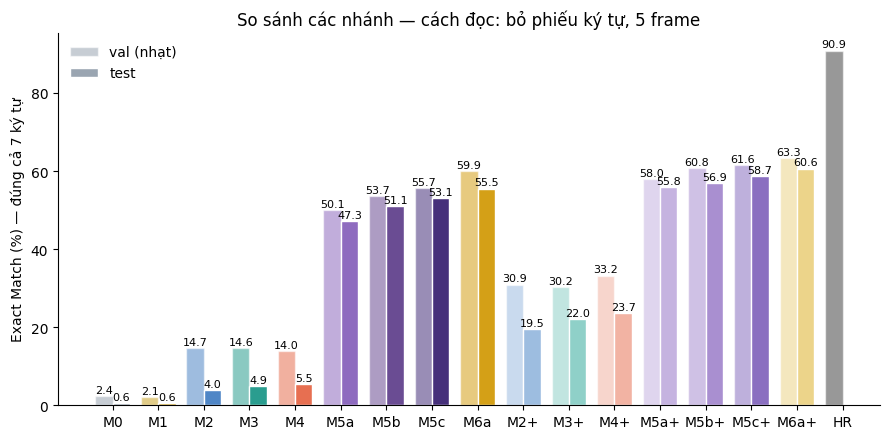

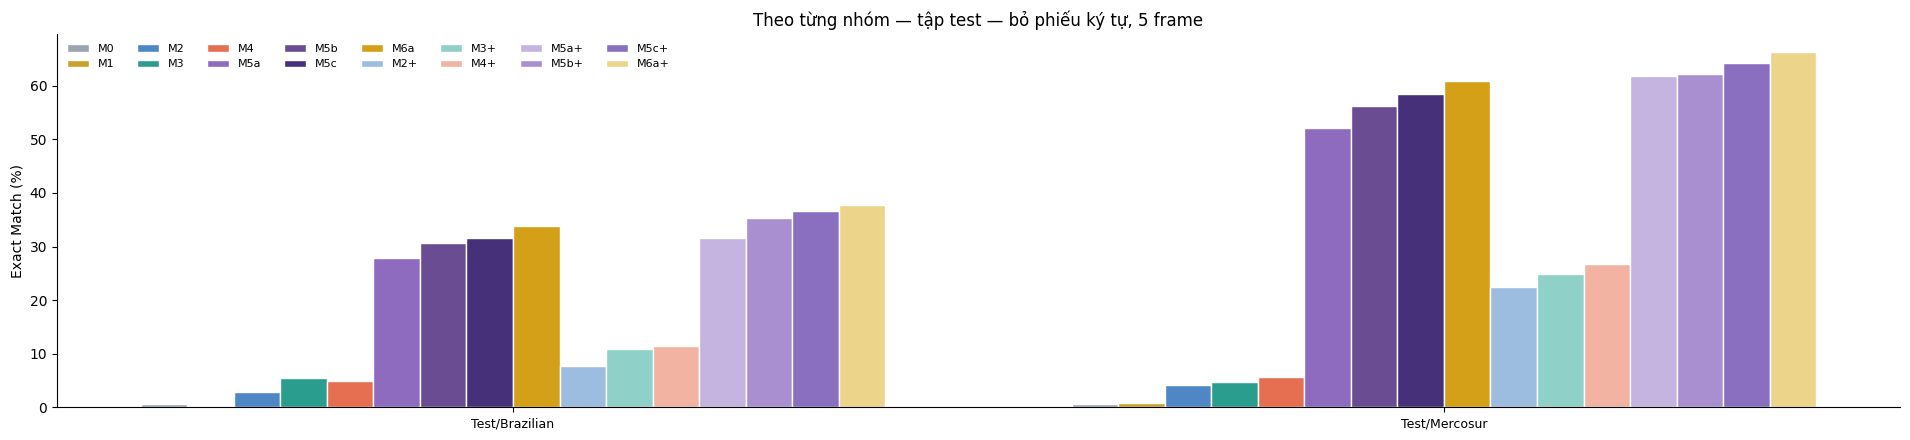

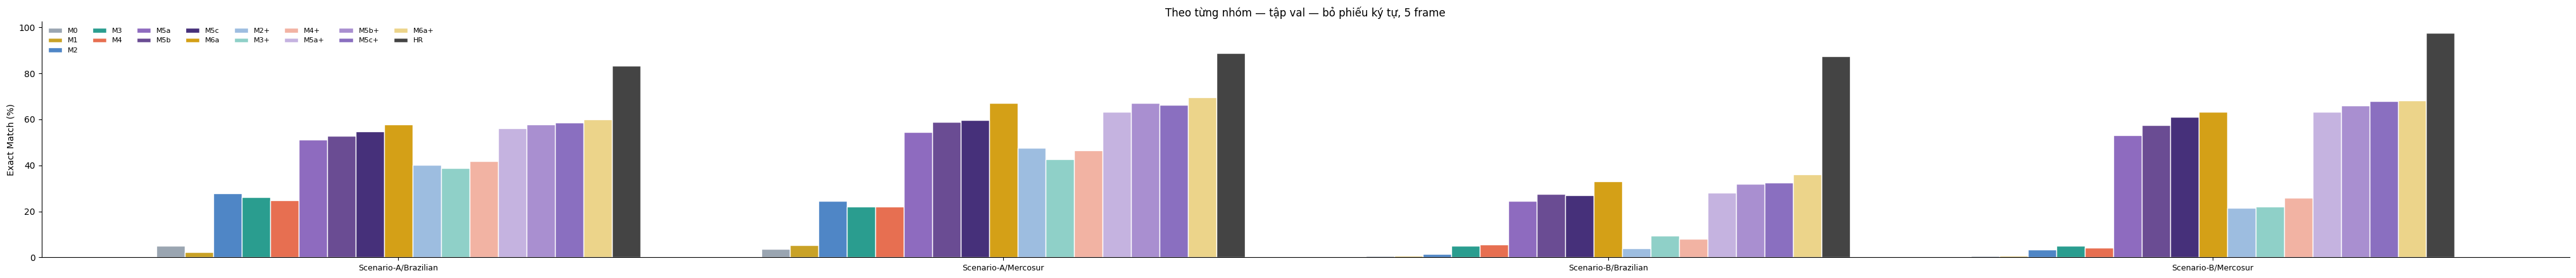

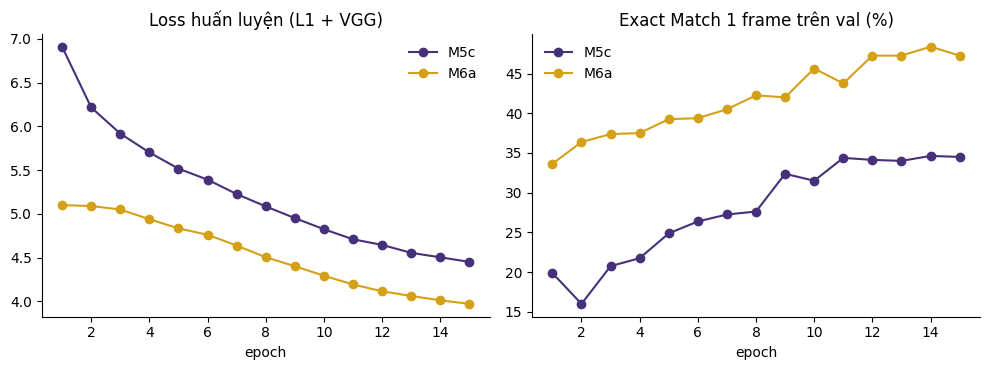

In [ ]:
with C.StepTimer('W3 · Tổng hợp kết quả vòng 3', EVID_DIR, TIMING):
    summary = R.gather_summary(RESULTS_DIR, out_csv=f'{RESULTS_DIR}/summary.csv')
    chosen = C.read_json(f'{RESULTS_DIR}/chosen_on_val_v3.json')
    fusion, best = chosen['cach_gop_tot_nhat'], chosen['mo_hinh_tot_nhat']
    ms = C.read_json(f'{RESULTS_DIR}/speed_ms_per_image_v3.json') if os.path.exists(f'{RESULTS_DIR}/speed_ms_per_image_v3.json') else {}
    R.write_comparison_md(f'{RESULTS_DIR}/comparison_v3.md', summary, chosen, f'{EVID_DIR}/{TIMING}', ms)
    R.plot_overview(summary, fusion, f'{RESULTS_DIR}/so_sanh_tong_quan_v3.png')
    R.plot_groups(summary, fusion, 'test', f'{RESULTS_DIR}/so_sanh_theo_nhom_test_v3.png')
    R.plot_groups(summary, fusion, 'val', f'{RESULTS_DIR}/so_sanh_theo_nhom_val_v3.png')
    logs = {b: f'{CKPT_DIR}/lpsrgan_{b}/train_log.csv' for b in ['M5c'] + list(M6)}
    R.plot_training(logs, f'{RESULTS_DIR}/duong_cong_huan_luyen_v3.png')
    R.confusion_pairs(RESULTS_DIR, fusion, f'{RESULTS_DIR}/confusion_pairs_v3.csv')
    store = R.ResultStore(RESULTS_DIR)
    made = R.make_examples(store, 'test', fusion, best, f'{RESULTS_DIR}/examples_v3')
print(open(f'{RESULTS_DIR}/comparison_v3.md', encoding='utf-8').read())

### Biểu đồ

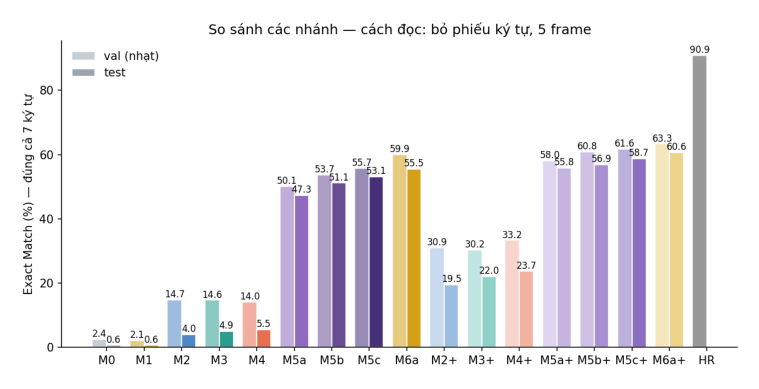

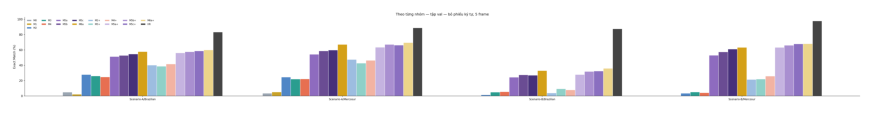

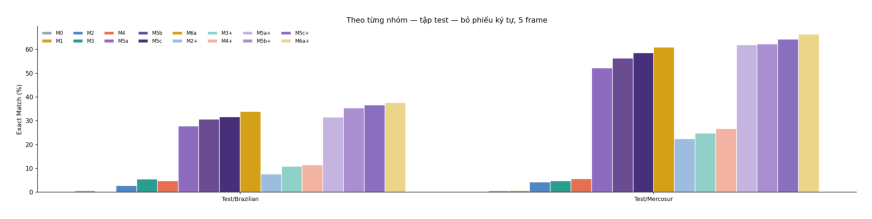

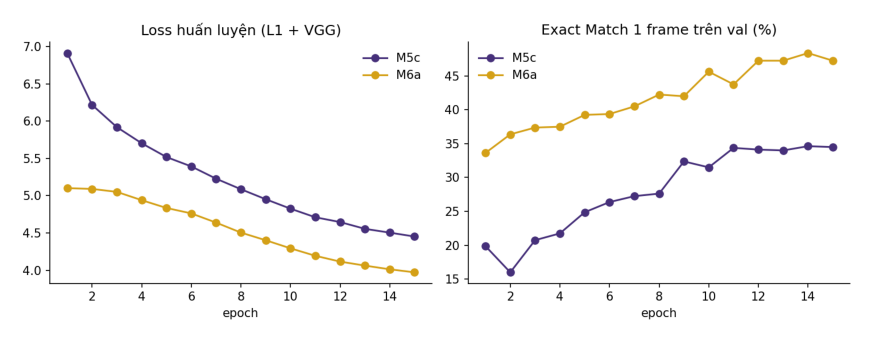

In [ ]:
import matplotlib.pyplot as plt, matplotlib.image as mpimg
for p in ('so_sanh_tong_quan_v3.png', 'so_sanh_theo_nhom_val_v3.png', 'so_sanh_theo_nhom_test_v3.png', 'duong_cong_huan_luyen_v3.png'):
    if os.path.exists(f'{RESULTS_DIR}/{p}'):
        plt.figure(figsize=(11, 4.8)); plt.imshow(mpimg.imread(f'{RESULTS_DIR}/{p}')); plt.axis('off'); plt.show()

### Xem ảnh các nhánh cạnh nhau
Đổi `TRACK` để xem một track cụ thể (cột `track` trong `pred_test.csv`), để trống để xem các ca tiêu biểu.
Với nhánh nhiều frame, 5 ảnh là 5 lần chạy (mỗi lần một frame làm tâm).

— gan_dung_cv_sai : ['test/track_19614']


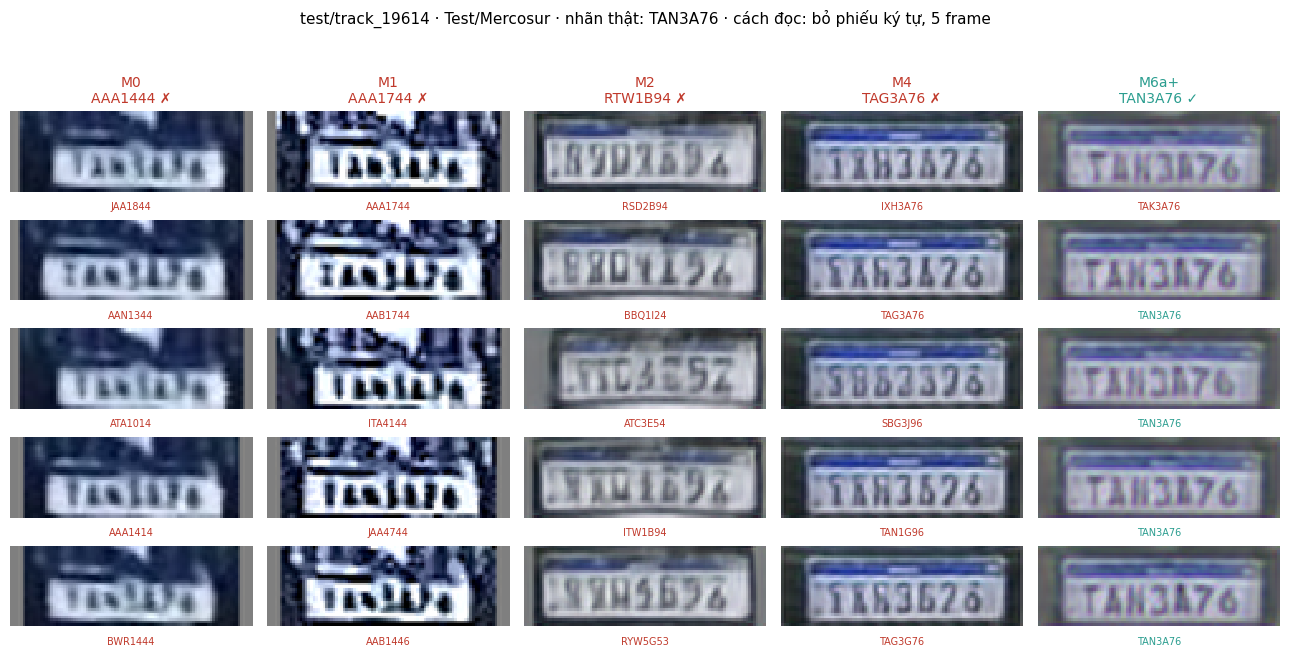

— ao_giac : ['test/track_12193']


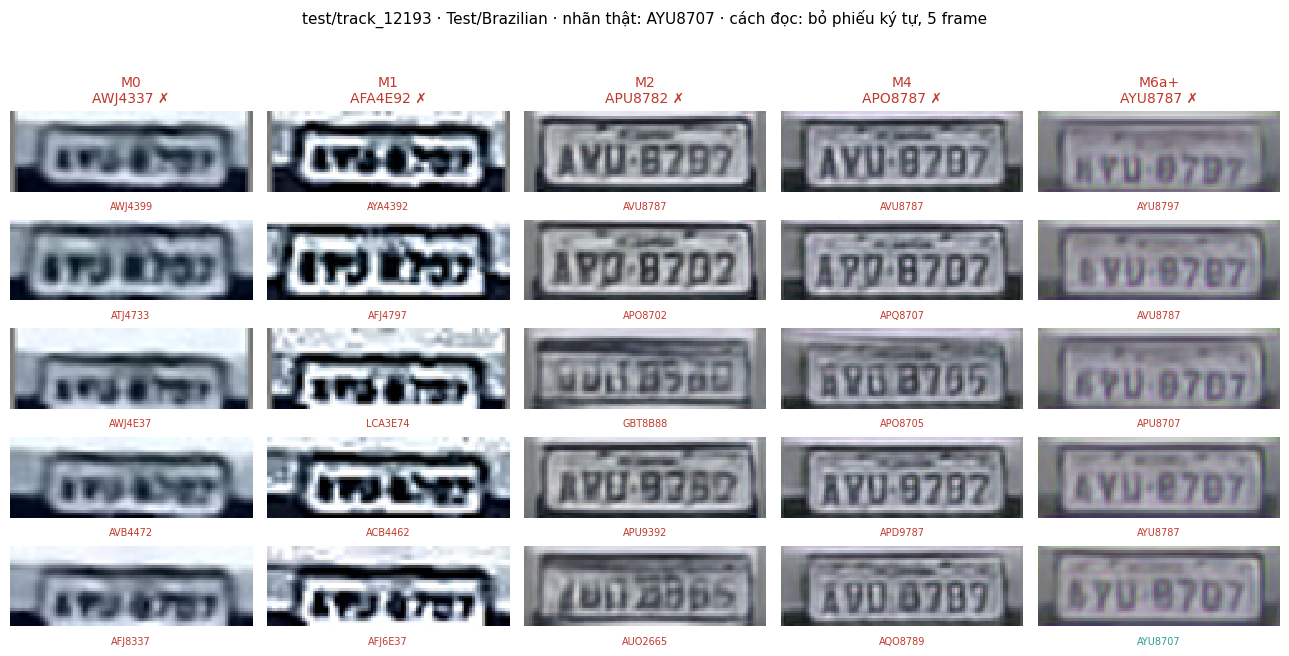

— dem : []
— ngay : []
— brazilian : ['test/track_10039']


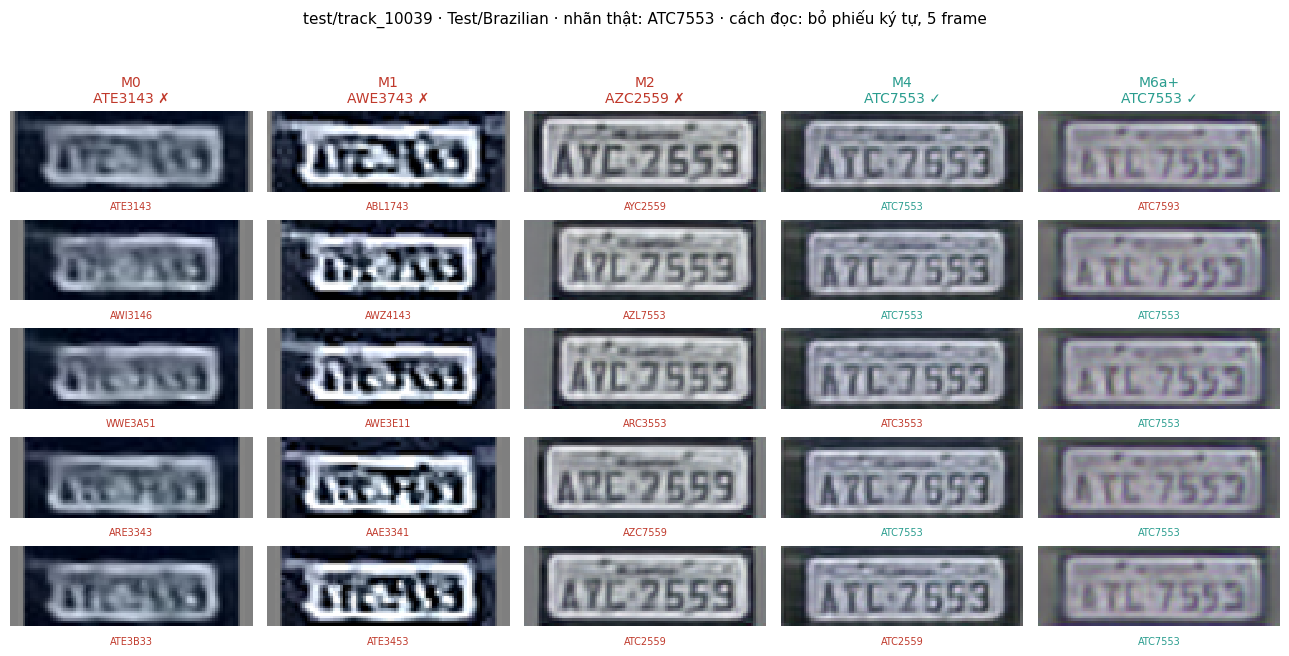

— mercosur : ['test/track_22421']


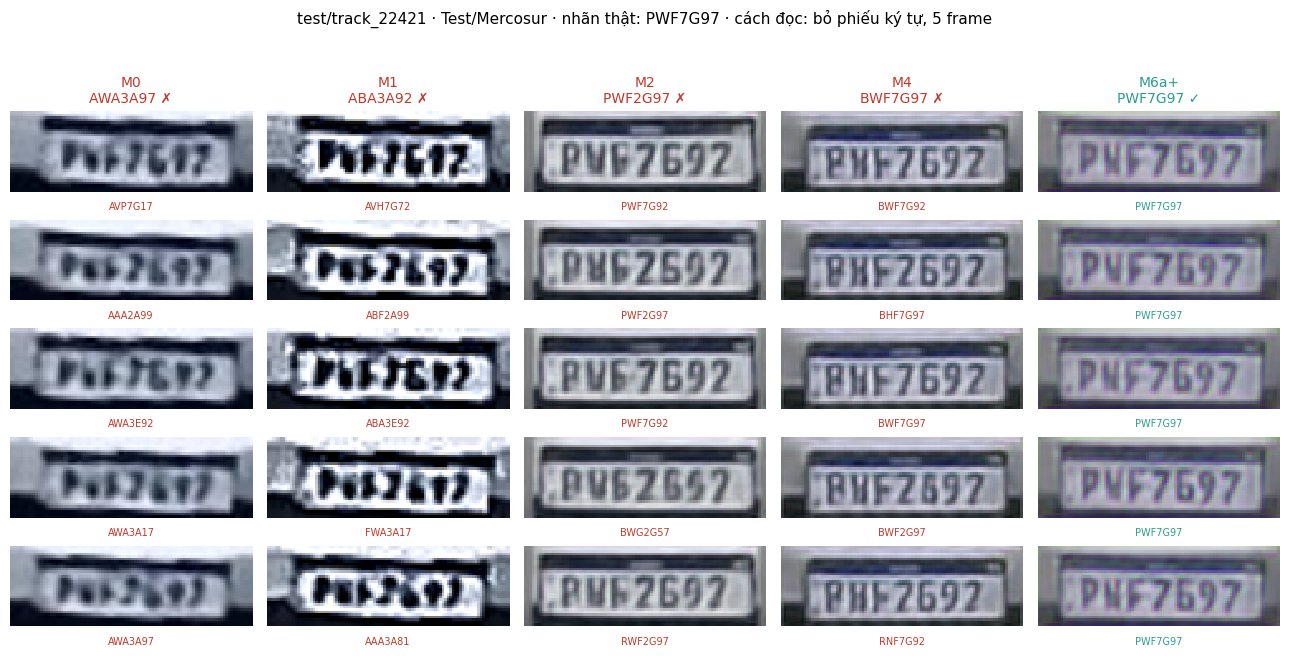

— sai_het : ['test/track_13198']


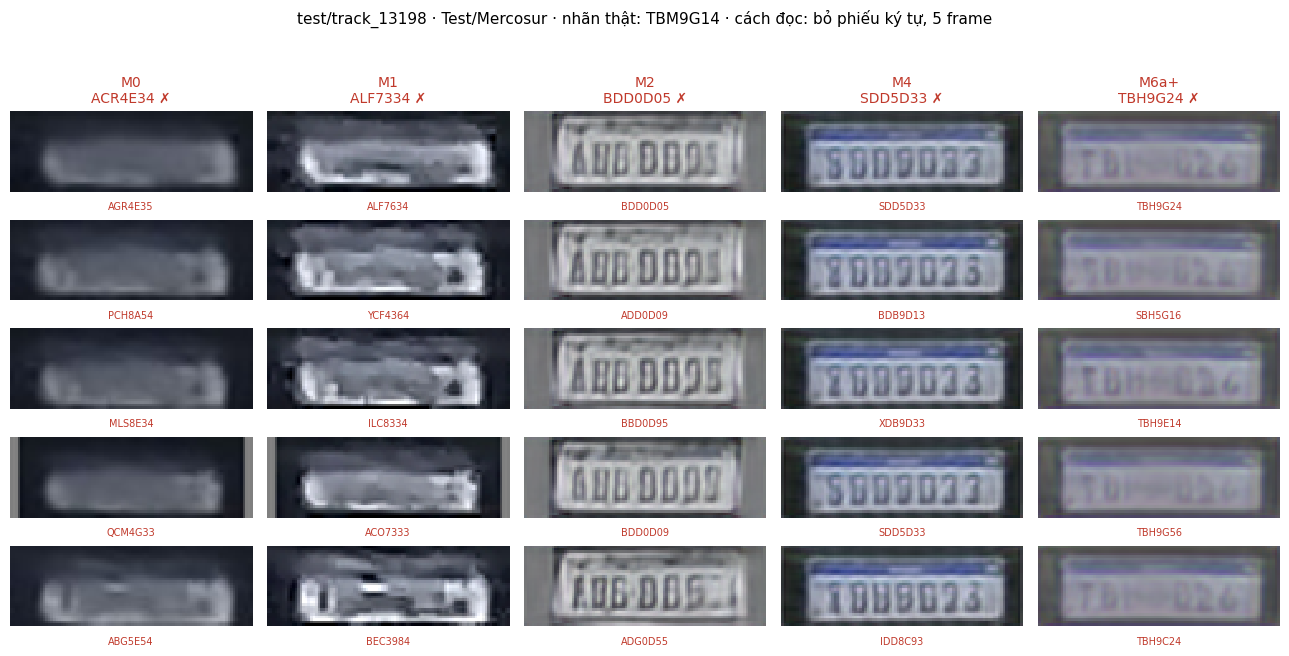

In [ ]:
TRACK = ''
SPLIT_SHOW = 'test'
store = R.ResultStore(RESULTS_DIR)
chosen = C.read_json(f'{RESULTS_DIR}/chosen_on_val_v3.json')
fusion, best = chosen['cach_gop_tot_nhat'], chosen['mo_hinh_tot_nhat']
if TRACK:
    R.show_track(store, TRACK, SPLIT_SHOW, fusion, best=best)
else:
    for cat, tracks in R.pick_examples(store, SPLIT_SHOW, fusion, best).items():
        print('—', cat, ':', tracks)
        for t in tracks:
            R.show_track(store, t, SPLIT_SHOW, fusion, best=best)

### Đóng gói bằng chứng vòng 3

In [ ]:
import zipfile
n = R.write_manifest({'results': RESULTS_DIR, 'evidence': EVID_DIR, 'splits': SPLIT_DIR, 'ckpt': CKPT_DIR},
                     f'{EVID_DIR}/MANIFEST.json')
print('MANIFEST.json:', n, 'file')
bundle = f'{DRIVE_DIR}/ket_qua_v3_gui_thay.zip'
with zipfile.ZipFile(bundle, 'w', zipfile.ZIP_DEFLATED) as z:
    for name, root in {'results': RESULTS_DIR, 'evidence': EVID_DIR, 'splits': SPLIT_DIR, 'ckpt': CKPT_DIR}.items():
        for dp, _, fns in os.walk(root):
            for fn in fns:
                if fn.endswith(('.npz', '.pth', '.tmp')):
                    continue
                p = os.path.join(dp, fn)
                z.write(p, os.path.join(name, os.path.relpath(p, root)))
print(f'Đã tạo {bundle} ({os.path.getsize(bundle) / 1e6:.1f} MB)')

MANIFEST.json: 183 file
Đã tạo /content/drive/MyDrive/MyCV/ket_qua_v3_gui_thay.zip (10.1 MB)
